In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit

# Project root: ADLCS Proj/
PROJECT_ROOT = Path.cwd()

# If your notebook is running from notebooks/02_preprocessing/,
# move two levels up to reach the project root.
if PROJECT_ROOT.name == "02_preprocessing":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "EDA_Full_Dataset.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "splits"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())

Project root: /Users/ananyosen/Documents/ADLCS Proj
Dataset exists: True


In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nReadmission values:")
print(df["readmitted"].value_counts(dropna=False))

Dataset shape: (101766, 56)


,encounter_id,num_medications,metformin-pioglitazone,diabetesMed,metformin-rosiglitazone,diag_1,glimepiride,chlorpropamide,nateglinide,tolbutamide,...,A1Cresult_missing,medical_specialty_missing,diag_2,readmitted,number_diagnoses,admission_source_id,glipizide-metformin,number_outpatient,acetohexamide,diag_2_missing
0,2278392,1,No,No,No,250.83,No,No,No,No,...,True,False,Unknown,NO,1,1,No,0,No,True
1,149190,18,No,Yes,No,276,No,No,No,No,...,True,True,250.01,>30,9,7,No,0,No,False
2,64410,13,No,Yes,No,648,No,No,No,No,...,True,True,250,NO,6,7,No,2,No,False
3,500364,16,No,Yes,No,8,No,No,No,No,...,True,True,250.43,NO,7,7,No,0,No,False
4,16680,8,No,Yes,No,197,No,No,No,No,...,True,True,157,NO,5,7,No,0,No,False



Column names:
['encounter_id', 'num_medications', 'metformin-pioglitazone', 'diabetesMed', 'metformin-rosiglitazone', 'diag_1', 'glimepiride', 'chlorpropamide', 'nateglinide', 'tolbutamide', 'diag_1_missing', 'diag_3', 'num_procedures', 'acarbose', 'time_in_hospital', 'discharge_disposition_id', 'insulin', 'diag_3_missing', 'age_min', 'age_max', 'glyburide-metformin', 'change', 'number_emergency', 'payer_code', 'number_inpatient', 'repaglinide', 'rosiglitazone', 'glyburide', 'payer_code_missing', 'patient_nbr', 'glimepiride-pioglitazone', 'pioglitazone', 'admission_type_id', 'glipizide', 'num_lab_procedures', 'troglitazone', 'race', 'race_missing', 'max_glu_serum', 'gender', 'tolazamide', 'miglitol', 'metformin', 'medical_specialty', 'A1Cresult', 'max_glu_serum_missing', 'A1Cresult_missing', 'medical_specialty_missing', 'diag_2', 'readmitted', 'number_diagnoses', 'admission_source_id', 'glipizide-metformin', 'number_outpatient', 'acetohexamide', 'diag_2_missing']

Readmission values:


In [3]:
df["readmitted"] = df["readmitted"].astype("string").str.strip()

target_map = {
    "<30": 1,
    "NO": 0,
    ">30": 0
}

df["readmission_30d"] = df["readmitted"].map(target_map)

# Check for unexpected or missing target values
print("Unmapped target values:")
print(df.loc[df["readmission_30d"].isna(), "readmitted"].value_counts(dropna=False))

# Stop if any target cannot be mapped
if df["readmission_30d"].isna().any():
    raise ValueError("Some readmission labels could not be mapped. Inspect them before continuing.")

df["readmission_30d"] = df["readmission_30d"].astype("int8")

print("\nBinary target distribution:")
print(df["readmission_30d"].value_counts())
print("\nTarget percentages:")
print((df["readmission_30d"].value_counts(normalize=True) * 100).round(2))

Unmapped target values:
Series([], Name: count, dtype: int64[pyarrow])

Binary target distribution:
readmission_30d
0    90409
1    11357
Name: count, dtype: int64

Target percentages:
readmission_30d
0    88.84
1    11.16
Name: proportion, dtype: float64


In [4]:
identifier_columns = [
    "encounter_id",
    "patient_nbr"
]

target_columns = [
    "readmitted",
    "readmission_30d"
]

# These columns should not be model inputs.
excluded_columns = identifier_columns + target_columns

# Keep patient_nbr separately for patient-grouped splitting.
groups = df["patient_nbr"].copy()

X = df.drop(columns=[c for c in excluded_columns if c in df.columns])
y = df["readmission_30d"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Patient groups:", groups.nunique())
print("Excluded columns:", [c for c in excluded_columns if c in df.columns])

Feature matrix shape: (101766, 53)
Target shape: (101766,)
Patient groups: 71518
Excluded columns: ['encounter_id', 'patient_nbr', 'readmitted', 'readmission_30d']


In [5]:
# First split: 15% test, 85% development data
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

development_idx, test_idx = next(
    split_1.split(X, y, groups=groups)
)

# Second split: validation is 15% of the full dataset.
# Since 85% remains, 15/85 = 0.17647 of development data.
validation_fraction = 0.15 / 0.85

split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=validation_fraction,
    random_state=42
)

train_relative_idx, validation_relative_idx = next(
    split_2.split(
        X.iloc[development_idx],
        y.iloc[development_idx],
        groups=groups.iloc[development_idx]
    )
)

train_idx = development_idx[train_relative_idx]
validation_idx = development_idx[validation_relative_idx]

# Build split dataframes.
# patient_nbr is retained only for grouping/auditing, never as a model feature.
def create_split(indices):
    result = X.iloc[indices].copy()
    result["readmission_30d"] = y.iloc[indices].values
    result["patient_nbr"] = groups.iloc[indices].values
    return result.reset_index(drop=True)

train_df = create_split(train_idx)
validation_df = create_split(validation_idx)
test_df = create_split(test_idx)

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (71395, 55)
Validation: (15263, 55)
Test: (15108, 55)


In [6]:
train_patients = set(train_df["patient_nbr"])
validation_patients = set(validation_df["patient_nbr"])
test_patients = set(test_df["patient_nbr"])

print("Train-validation overlap:", len(train_patients & validation_patients))
print("Train-test overlap:", len(train_patients & test_patients))
print("Validation-test overlap:", len(validation_patients & test_patients))

assert len(train_patients & validation_patients) == 0
assert len(train_patients & test_patients) == 0
assert len(validation_patients & test_patients) == 0

print("\nPatient-level split verification passed.")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Patient-level split verification passed.


In [7]:
def split_summary(name, split_df):
    total = len(split_df)
    positives = int(split_df["readmission_30d"].sum())

    return {
        "Split": name,
        "Rows": total,
        "Patients": split_df["patient_nbr"].nunique(),
        "Positive cases": positives,
        "Positive rate (%)": round(100 * positives / total, 2)
    }

summary = pd.DataFrame([
    split_summary("Train", train_df),
    split_summary("Validation", validation_df),
    split_summary("Test", test_df)
])

display(summary)

,Split,Rows,Patients,Positive cases,Positive rate (%)
0,Train,71395,50062,8019,11.23
1,Validation,15263,10728,1696,11.11
2,Test,15108,10728,1642,10.87


In [8]:
train_df.to_csv(OUTPUT_DIR / "train.csv", index=False)
validation_df.to_csv(OUTPUT_DIR / "validation.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test.csv", index=False)

summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

manifest = {
    "random_state": 42,
    "split_method": "GroupShuffleSplit",
    "group_column": "patient_nbr",
    "target_column": "readmission_30d",
    "target_mapping": {
        "<30": 1,
        "NO": 0,
        ">30": 0
    },
    "excluded_from_model_features": [
        "encounter_id",
        "patient_nbr",
        "readmitted",
        "readmission_30d"
    ],
    "note": "patient_nbr is retained in split CSVs for auditing only. Drop it before model training."
}

with open(OUTPUT_DIR / "split_manifest.json", "w") as f:
    json.dump(manifest, f, indent=4)

print("Saved split files to:", OUTPUT_DIR)

Saved split files to: /Users/ananyosen/Documents/ADLCS Proj/data/processed/splits


In [9]:
# Inspect data types
dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": [
        df[col].nunique(dropna=False) for col in df.columns
    ],
    "Missing Values": df.isna().sum().values,
    "Missing Percentage": (
        df.isna().mean().values * 100
    ).round(2)
})

dtype_summary = dtype_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(dtype_summary.to_string(index=False))

'                   Column Data Type  Unique Values  Missing Values  Missing Percentage\n             encounter_id     int64         101766               0                 0.0\n              patient_nbr     int64          71518               0                 0.0\n             pioglitazone       str              4               0                 0.0\n        admission_type_id     int64              8               0                 0.0\n                glipizide       str              4               0                 0.0\n       num_lab_procedures     int64            118               0                 0.0\n             troglitazone       str              2               0                 0.0\n                     race       str              6               0                 0.0\n             race_missing      bool              2               0                 0.0\n            max_glu_serum       str              4               0                 0.0\n                   gender      

In [10]:
# Numerical columns
numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))

print("\nNumerical:")
print(numerical_columns)

print("\nCategorical:")
print(categorical_columns)

Numerical columns: 13
Categorical columns: 40

Numerical:
['num_medications', 'num_procedures', 'time_in_hospital', 'discharge_disposition_id', 'age_min', 'age_max', 'number_emergency', 'number_inpatient', 'admission_type_id', 'num_lab_procedures', 'number_diagnoses', 'admission_source_id', 'number_outpatient']

Categorical:
['metformin-pioglitazone', 'diabetesMed', 'metformin-rosiglitazone', 'diag_1', 'glimepiride', 'chlorpropamide', 'nateglinide', 'tolbutamide', 'diag_1_missing', 'diag_3', 'acarbose', 'insulin', 'diag_3_missing', 'glyburide-metformin', 'change', 'payer_code', 'repaglinide', 'rosiglitazone', 'glyburide', 'payer_code_missing', 'glimepiride-pioglitazone', 'pioglitazone', 'glipizide', 'troglitazone', 'race', 'race_missing', 'max_glu_serum', 'gender', 'tolazamide', 'miglitol', 'metformin', 'medical_specialty', 'A1Cresult', 'max_glu_serum_missing', 'A1Cresult_missing', 'medical_specialty_missing', 'diag_2', 'glipizide-metformin', 'acetohexamide', 'diag_2_missing']


In [11]:
print("Original dataset columns:", len(df.columns))
print("Feature matrix columns:", len(X.columns))

excluded = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "readmission_30d"
]

print("\nExcluded columns still present:")
print([c for c in excluded if c in X.columns])

print("\nColumns in X but not expected:")
print(sorted(set(X.columns) - (set(df.columns) - set(excluded))))

print("\nExpected feature count:", len(set(df.columns) - set(excluded)))

Original dataset columns: 57
Feature matrix columns: 53

Excluded columns still present:
[]

Columns in X but not expected:
[]

Expected feature count: 53


In [12]:
categorical_audit = []

for col in categorical_columns:
    categorical_audit.append({
        "Feature": col,
        "Unique Categories": X[col].nunique(dropna=False),
        "Top 5 Values": X[col].value_counts(dropna=False).head(5).to_dict()
    })

categorical_audit_df = pd.DataFrame(categorical_audit)

categorical_audit_df = categorical_audit_df.sort_values(
    by="Unique Categories",
    ascending=False
)

display(categorical_audit_df.to_string(index=False))

"                  Feature  Unique Categories                                                                                                                Top 5 Values\n                   diag_3                790                                                          {'250': 11555, '401': 8289, '276': 5175, '428': 4577, '427': 3955}\n                   diag_2                749                                                           {'276': 6752, '428': 6662, '250': 6071, '427': 5036, '401': 3736}\n                   diag_1                717                                                           {'428': 6862, '414': 6581, '786': 4016, '410': 3614, '486': 3508}\n        medical_specialty                 73 {'Unknown': 49949, 'InternalMedicine': 14635, 'Emergency/Trauma': 7565, 'Family/GeneralPractice': 7440, 'Cardiology': 5352}\n               payer_code                 18                                                         {'Unknown': 40256, 'MC': 32439, 'HM': 6274, 'SP'

In [13]:
numerical_audit = []

for col in numerical_columns:
    numerical_audit.append({
        "Feature": col,
        "Minimum": X[col].min(),
        "Maximum": X[col].max(),
        "Unique Values": X[col].nunique(),
        "Mean": round(X[col].mean(), 2),
        "Median": round(X[col].median(), 2)
    })

numerical_audit_df = pd.DataFrame(numerical_audit)

display(numerical_audit_df.to_string(index=False))

'                 Feature  Minimum  Maximum  Unique Values  Mean  Median\n         num_medications        1       81             75 16.02    15.0\n          num_procedures        0        6              7  1.34     1.0\n        time_in_hospital        1       14             14  4.40     4.0\ndischarge_disposition_id        1       28             26  3.72     1.0\n                 age_min        0       90             10 60.97    60.0\n                 age_max       10      100             10 70.97    70.0\n        number_emergency        0       76             33  0.20     0.0\n        number_inpatient        0       21             21  0.64     0.0\n       admission_type_id        1        8              8  2.02     1.0\n      num_lab_procedures        1      132            118 43.10    44.0\n        number_diagnoses        1       16             16  7.42     8.0\n     admission_source_id        1       25             17  5.75     7.0\n       number_outpatient        0       42        

In [14]:
from pathlib import Path
import pandas as pd

# Try the reorganised location first, then the original project location.
mapping_candidates = [
    PROJECT_ROOT / "data" / "raw" / "IDS_mapping.csv",
    PROJECT_ROOT / "IDS_mapping.csv"
]

mapping_path = next(
    (p for p in mapping_candidates if p.exists()),
    None
)

if mapping_path is None:
    raise FileNotFoundError("IDS_mapping.csv was not found.")

mapping_df = pd.read_csv(mapping_path)

print("Mapping file shape:", mapping_df.shape)
print("Columns:", mapping_df.columns.tolist())

display(mapping_df.head(30))

Mapping file shape: (67, 2)
Columns: ['admission_type_id', 'description']


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


In [15]:
diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

for col in diagnosis_columns:
    values = X[col].astype("string").str.strip()

    print(f"\n--- {col} ---")
    print("Unique values:", values.nunique())
    print("Examples:", values.dropna().unique()[:25])

    print("\nMost common values:")
    display(values.value_counts().head(15))


--- diag_1 ---
Unique values: 717
Examples: <ArrowStringArray>
['250.83',    '276',    '648',      '8',    '197',    '414',    '428',
    '398',    '434',  '250.7',    '157',    '518',    '999',    '410',
    '682',    '402',    '737',    '572',    'V57',    '189',    '786',
    '427',    '996',    '277',    '584']
Length: 25, dtype: string

Most common values:


diag_1
428      6862
414      6581
786      4016
410      3614
486      3508
427      2766
491      2275
715      2151
682      2042
434      2028
780      2019
996      1967
276      1889
38       1688
250.8    1680
Name: count, dtype: int64[pyarrow]


--- diag_2 ---
Unique values: 749
Examples: <ArrowStringArray>
['Unknown',  '250.01',     '250',  '250.43',     '157',     '411',     '492',
     '427',     '198',     '403',     '288',     '998',     '507',     '174',
     '425',     '456',     '401',     '715',     '496',     '428',     '585',
  '250.02',     '410',     '999',     '996']
Length: 25, dtype: string

Most common values:


diag_2
276       6752
428       6662
250       6071
427       5036
401       3736
496       3305
599       3288
403       2823
414       2650
411       2566
250.02    2074
707       1999
585       1871
584       1649
491       1545
Name: count, dtype: int64[pyarrow]


--- diag_3 ---
Unique values: 790
Examples: <ArrowStringArray>
['Unknown',     '255',     'V27',     '403',     '250',     'V45',      '38',
     '486',     '996',     '197',   '250.6',     '427',     '627',     '414',
     '416',     '714',     '428',     '582',     'V43',  '250.01',     '263',
  '250.42',     '276',     '482',     '401']
Length: 25, dtype: string

Most common values:


diag_3
250        11555
401         8289
276         5175
428         4577
427         3955
414         3664
496         2605
403         2357
585         1992
272         1969
599         1941
Unknown     1423
V45         1389
250.02      1369
707         1360
Name: count, dtype: int64[pyarrow]

In [16]:
age_summary = (
    X[["age_min", "age_max"]]
    .value_counts()
    .sort_index()
    .reset_index(name="Records")
)

display(age_summary)

,age_min,age_max,Records
0,0,10,161
1,10,20,691
2,20,30,1657
3,30,40,3775
4,40,50,9685
5,50,60,17256
6,60,70,22483
7,70,80,26068
8,80,90,17197
9,90,100,2793


In [17]:
mapping_raw = pd.read_csv(
    mapping_path,
    header=None,
    dtype=str
)

# Display all rows, including section headings
pd.set_option("display.max_rows", 100)

display(mapping_raw.to_string(index=True))

'                           0                                                                                                          1\n0          admission_type_id                                                                                                description\n1                          1                                                                                                  Emergency\n2                          2                                                                                                     Urgent\n3                          3                                                                                                   Elective\n4                          4                                                                                                    Newborn\n5                          5                                                                                              Not Available\n6                          6            

In [18]:
id_columns = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

for col in id_columns:
    print(f"\n--- {col} ---")
    print("Values found in dataset:")
    print(sorted(X[col].dropna().unique().tolist()))

    print("Value counts:")
    display(X[col].value_counts().sort_index())


--- admission_type_id ---
Values found in dataset:
[1, 2, 3, 4, 5, 6, 7, 8]
Value counts:


admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64


--- discharge_disposition_id ---
Values found in dataset:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 27, 28]
Value counts:


discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64


--- admission_source_id ---
Values found in dataset:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 17, 20, 22, 25]
Value counts:


admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64

In [19]:
# age_min in your dataset is actually the lower boundary
# of the original age interval.

X["age_midpoint"] = X["age_min"] + 5

# Remove the two redundant age representations
X = X.drop(columns=["age_min", "age_max"])

print(X[["age_midpoint"]].describe())
print("\nAge midpoint distribution:")
display(X["age_midpoint"].value_counts().sort_index())

        age_midpoint
count  101766.000000
mean       65.967022
std        15.940838
min         5.000000
25%        55.000000
50%        65.000000
75%        75.000000
max        95.000000

Age midpoint distribution:


age_midpoint
5       161
15      691
25     1657
35     3775
45     9685
55    17256
65    22483
75    26068
85    17197
95     2793
Name: count, dtype: int64

In [20]:
mapping_raw = pd.read_csv(
    mapping_path,
    header=None,
    dtype="string"
)

mapping_sections = {}

section_names = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

current_section = None

for _, row in mapping_raw.iterrows():

    first = str(row.iloc[0]).strip()
    second = row.iloc[1]

    if first in section_names:
        current_section = first
        mapping_sections[current_section] = {}
        continue

    if current_section is None:
        continue

    # Ignore empty separator rows
    if pd.isna(row.iloc[0]):
        continue

    try:
        code = int(first)
    except ValueError:
        continue

    description = (
        "Unknown/Unmapped"
        if pd.isna(second) or str(second).strip() == ""
        else str(second).strip()
    )

    mapping_sections[current_section][code] = description


for section, mapping in mapping_sections.items():
    print(f"\n{section}: {len(mapping)} mappings")
    print(mapping)


admission_type_id: 8 mappings
{1: 'Emergency', 2: 'Urgent', 3: 'Elective', 4: 'Newborn', 5: 'Not Available', 6: 'Unknown/Unmapped', 7: 'Trauma Center', 8: 'Not Mapped'}

discharge_disposition_id: 30 mappings
{1: 'Discharged to home', 2: 'Discharged/transferred to another short term hospital', 3: 'Discharged/transferred to SNF', 4: 'Discharged/transferred to ICF', 5: 'Discharged/transferred to another type of inpatient care institution', 6: 'Discharged/transferred to home with home health service', 7: 'Left AMA', 8: 'Discharged/transferred to home under care of Home IV provider', 9: 'Admitted as an inpatient to this hospital', 10: 'Neonate discharged to another hospital for neonatal aftercare', 11: 'Expired', 12: 'Still patient or expected to return for outpatient services', 13: 'Hospice / home', 14: 'Hospice / medical facility', 15: 'Discharged/transferred within this institution to Medicare approved swing bed', 16: 'Discharged/transferred/referred another institution for outpatient s

In [21]:
X = X.copy()

for col in section_names:

    X[col] = X[col].map(mapping_sections[col])

    X[col] = X[col].fillna("Unknown/Unmapped")

    X[col] = X[col].astype("string")

print("Mapping applied successfully.")

for col in section_names:
    print(f"\n{col}")
    display(X[col].value_counts().head(15))

Mapping applied successfully.

admission_type_id


admission_type_id
Emergency           53990
Elective            18869
Urgent              18480
Unknown/Unmapped     5291
Not Available        4785
Not Mapped            320
Trauma Center          21
Newborn                10
Name: count, dtype: int64[pyarrow]


discharge_disposition_id


discharge_disposition_id
Discharged to home                                                                                           60234
Discharged/transferred to SNF                                                                                13954
Discharged/transferred to home with home health service                                                      12902
Unknown/Unmapped                                                                                              3691
Discharged/transferred to another short term hospital                                                         2128
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1993
Expired                                                                                                       1642
Discharged/transferred to another type of inpatient care institution                                          1184
Not Mapped                                             


admission_source_id


admission_source_id
Emergency Room                                               57494
Physician Referral                                           29565
Unknown/Unmapped                                              6781
Transfer from a hospital                                      3187
Transfer from another health care facility                    2264
Clinic Referral                                               1104
Transfer from a Skilled Nursing Facility (SNF)                 855
HMO Referral                                                   187
Not Mapped                                                     161
Not Available                                                  125
Court/Law Enforcement                                           16
Transfer from hospital inpt/same fac reslt in a sep claim       12
Transfer from critial access hospital                            8
Extramural Birth                                                 2
Normal Delivery                           

In [22]:
diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

for col in diagnosis_columns:
    print(f"\n--- {col} ---")

    codes = X[col].astype("string").str.strip()

    print("Numeric codes:",
          codes.str.match(r"^\d+(\.\d+)?$", na=False).sum())

    print("V codes:",
          codes.str.match(r"^V", case=False, na=False).sum())

    print("E codes:",
          codes.str.match(r"^E", case=False, na=False).sum())

    print("Unknown values:",
          codes.eq("Unknown").sum())

    print("Other formats:",
          codes[
              ~codes.str.match(r"^\d+(\.\d+)?$", na=False)
              & ~codes.str.match(r"^[VE]", case=False, na=False)
              & ~codes.eq("Unknown")
          ].unique()[:20])


--- diag_1 ---
Numeric codes: 100100
V codes: 1644
E codes: 1
Unknown values: 21
Other formats: <ArrowStringArray>
[]
Length: 0, dtype: string

--- diag_2 ---
Numeric codes: 98872
V codes: 1805
E codes: 731
Unknown values: 358
Other formats: <ArrowStringArray>
[]
Length: 0, dtype: string

--- diag_3 ---
Numeric codes: 95285
V codes: 3814
E codes: 1244
Unknown values: 1423
Other formats: <ArrowStringArray>
[]
Length: 0, dtype: string


In [23]:
for col in diagnosis_columns:
    codes = X[col].astype("string").str.strip()

    decimal_codes = codes[
        codes.str.match(r"^\d+\.\d+$", na=False)
    ]

    print(f"\n{col}")
    print("Decimal code count:", len(decimal_codes))
    print("Examples:", decimal_codes.unique()[:20])


diag_1
Decimal code count: 8522
Examples: <ArrowStringArray>
['250.83',  '250.7',  '250.6',  '250.4', '250.11', '250.32', '250.13',
 '250.03',  '250.8', '250.02', '250.42', '250.41', '250.22', '250.82',
 '250.33', '250.12', '250.81', '250.93', '250.01', '250.31']
Length: 20, dtype: string

diag_2
Decimal code count: 6723
Examples: <ArrowStringArray>
['250.01', '250.43', '250.02', '250.03', '250.52',  '250.6', '250.82',
 '250.51', '250.42', '250.41', '250.13', '250.12', '250.53', '250.93',
  '250.7', '250.83', '250.11', '250.81',  '250.5', '250.91']
Length: 20, dtype: string

diag_3
Decimal code count: 5603
Examples: <ArrowStringArray>
[ '250.6', '250.01', '250.42', '250.41', '250.02',  '250.8',  '250.7',
 '250.52', '250.82', '250.03',  '250.4', '250.51', '250.43', '250.92',
 '250.23', '250.53', '250.83',  '250.5', '250.91', '250.13']
Length: 20, dtype: string


In [24]:
import re

def extract_icd9_category(code):

    if pd.isna(code):
        return "Unknown"

    code = str(code).strip().upper()

    if code in ["UNKNOWN", "", "NAN"]:
        return "Unknown"

    # V-codes
    if code.startswith("V"):
        match = re.match(r"^V(\d{2})", code)
        return f"V{match.group(1)}" if match else "V_OTHER"

    # E-codes
    if code.startswith("E"):
        match = re.match(r"^E(\d{3})", code)
        return f"E{match.group(1)}" if match else "E_OTHER"

    # Numeric ICD-9 codes
    match = re.match(r"^(\d{3})", code)

    if match:
        return match.group(1)

    return "Unknown"


for col in ["diag_1", "diag_2", "diag_3"]:

    X[f"{col}_group"] = X[col].apply(
        extract_icd9_category
    ).astype("string")

    print(f"\n{col}")
    print("Original categories:", X[col].nunique())
    print("Grouped categories:", X[f"{col}_group"].nunique())

    display(
        X[f"{col}_group"].value_counts().head(15)
    )


diag_1
Original categories: 717
Grouped categories: 647


diag_1_group
250        8757
428        6862
414        6581
786        4016
410        3614
486        3508
427        2766
Unknown    2667
491        2275
715        2151
682        2042
434        2028
780        2019
996        1967
276        1889
Name: count, dtype: int64[pyarrow]


diag_2
Original categories: 749
Grouped categories: 690


diag_2_group
250        12794
276         6752
428         6662
427         5036
401         3736
496         3305
599         3288
403         2823
414         2650
411         2566
707         1999
Unknown     1918
585         1871
584         1649
491         1545
Name: count, dtype: int64[pyarrow]


diag_3
Original categories: 790
Grouped categories: 732


diag_3_group
250        17157
401         8289
276         5175
428         4577
427         3955
414         3664
Unknown     2949
496         2605
403         2357
585         1992
272         1969
599         1941
V45         1389
707         1360
780         1334
Name: count, dtype: int64[pyarrow]

In [25]:
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:

    print(f"\n--- {col} ---")

    print("Unique categories:", X[col].nunique())

    print("Unknown count:", (X[col] == "Unknown").sum())

    print("V-code count:", X[col].str.startswith("V").sum())

    print("E-code count:", X[col].str.startswith("E").sum())

    print("Sample categories:")
    print(X[col].unique()[:30])


--- diag_1_group ---
Unique categories: 647
Unknown count: 2667
V-code count: 1644
E-code count: 1
Sample categories:
<ArrowStringArray>
[    '250',     '276',     '648', 'Unknown',     '197',     '414',     '428',
     '398',     '434',     '157',     '518',     '999',     '410',     '682',
     '402',     '737',     '572',     'V57',     '189',     '786',     '427',
     '996',     '277',     '584',     '462',     '473',     '411',     '174',
     '486',     '998']
Length: 30, dtype: string

--- diag_2_group ---
Unique categories: 690
Unknown count: 1918
V-code count: 1805
E-code count: 731
Sample categories:
<ArrowStringArray>
['Unknown',     '250',     '157',     '411',     '492',     '427',     '198',
     '403',     '288',     '998',     '507',     '174',     '425',     '456',
     '401',     '715',     '496',     '428',     '585',     '410',     '999',
     '996',     '135',     '244',     '571',     '276',     '997',     '599',
     '424',     '491']
Length: 30, dtype: string


In [26]:
import re
import pandas as pd

def extract_icd9_category(code):

    if pd.isna(code):
        return "Unknown"

    code = str(code).strip().upper()

    if code in ["UNKNOWN", "", "NAN"]:
        return "Unknown"

    # V codes: preserve V + first two digits
    if code.startswith("V"):
        match = re.match(r"^V(\d{2})", code)
        return f"V{match.group(1)}" if match else code

    # E codes: preserve E + first three digits
    if code.startswith("E"):
        match = re.match(r"^E(\d{3})", code)
        return f"E{match.group(1)}" if match else code

    # Numeric ICD-9 codes
    match = re.match(r"^(\d+)(?:\.\d+)?$", code)

    if match:
        numeric_part = match.group(1)

        if len(numeric_part) >= 3:
            return numeric_part[:3]

        # Preserve short codes exactly
        return numeric_part

    # Preserve unusual original values rather than losing information
    return code

In [27]:
for col in ["diag_1", "diag_2", "diag_3"]:

    X[f"{col}_group"] = (
        X[col]
        .apply(extract_icd9_category)
        .astype("string")
    )

    print(f"\n--- {col} ---")

    print("Original categories:", X[col].nunique())
    print("Grouped categories:", X[f"{col}_group"].nunique())

    print("Original Unknown:",
          (X[col] == "Unknown").sum())

    print("Grouped Unknown:",
          (X[f"{col}_group"] == "Unknown").sum())


--- diag_1 ---
Original categories: 717
Grouped categories: 684
Original Unknown: 21
Grouped Unknown: 21

--- diag_2 ---
Original categories: 749
Grouped categories: 716
Original Unknown: 358
Grouped Unknown: 358

--- diag_3 ---
Original categories: 790
Grouped categories: 758
Original Unknown: 1423
Grouped Unknown: 1423


In [28]:
for col in ["diag_1", "diag_2", "diag_3"]:

    print(f"\n--- {col} ---")

    short_codes = X.loc[
        X[col].astype("string").str.fullmatch(r"\d{1,2}", na=False),
        col
    ].value_counts()

    print("Short numeric codes:")
    display(short_codes)

    print("Grouped Unknown count:",
          (X[f"{col}_group"] == "Unknown").sum())

    print("Original Unknown count:",
          (X[col] == "Unknown").sum())


--- diag_1 ---
Short numeric codes:


diag_1
38    1688
8      515
79      86
53      55
70      46
9       46
42      45
47      26
3       13
54      12
11      10
35      10
78       9
5        9
88       9
41       8
82       7
94       7
34       7
66       6
49       5
31       3
7        2
39       2
48       2
75       2
27       2
36       2
52       2
23       2
58       2
61       1
57       1
97       1
98       1
84       1
10       1
Name: count, dtype: int64

Grouped Unknown count: 21
Original Unknown count: 21

--- diag_2 ---
Short numeric codes:


diag_2
38    475
41    379
70    273
8     199
42     85
53     32
79     29
94     26
40     12
34     10
54     10
9       7
31      4
11      3
27      3
78      2
75      2
5       1
35      1
46      1
52      1
96      1
99      1
88      1
7       1
66      1
Name: count, dtype: int64

Grouped Unknown count: 358
Original Unknown count: 358

--- diag_3 ---
Short numeric codes:


diag_3
41    727
70    281
8     190
38    162
79     46
53     25
42     23
94     21
54     14
34      6
9       5
35      4
78      3
5       3
11      2
88      2
7       2
3       2
75      1
47      1
27      1
17      1
66      1
49      1
57      1
14      1
Name: count, dtype: int64

Grouped Unknown count: 1423
Original Unknown count: 1423


In [29]:
# Original diagnosis columns
original_diagnosis = [
    "diag_1",
    "diag_2",
    "diag_3"
]

# Grouped diagnosis columns
grouped_diagnosis = [
    "diag_1_group",
    "diag_2_group",
    "diag_3_group"
]

# Remove original diagnosis columns for Experiment B
X_grouped = X.drop(columns=original_diagnosis)

# Remove grouped diagnosis columns for Experiment A
X_original = X.drop(columns=grouped_diagnosis)

print("Experiment A - Original diagnosis codes")
print("Features:", X_original.shape[1])

print("\nExperiment B - Grouped diagnosis codes")
print("Features:", X_grouped.shape[1])

print("\nDiagnosis columns in Experiment B:")
print([c for c in X_grouped.columns if "diag_" in c])

Experiment A - Original diagnosis codes
Features: 52

Experiment B - Grouped diagnosis codes
Features: 52

Diagnosis columns in Experiment B:
['diag_1_missing', 'diag_3_missing', 'diag_2_missing', 'diag_1_group', 'diag_2_group', 'diag_3_group']


In [30]:
categorical_id_columns = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

# These should be categorical, not numerical.
for col in categorical_id_columns:
    X_grouped[col] = X_grouped[col].astype("string")
    X_original[col] = X_original[col].astype("string")

# Numerical features
numerical_features = [
    "num_medications",
    "num_procedures",
    "time_in_hospital",
    "age_midpoint",
    "number_emergency",
    "number_inpatient",
    "num_lab_procedures",
    "number_diagnoses",
    "number_outpatient"
]

# All remaining columns are treated as categorical.
categorical_features_grouped = [
    col for col in X_grouped.columns
    if col not in numerical_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features_grouped))
print("Total:", len(numerical_features) + len(categorical_features_grouped))

print("\nNumerical:")
print(numerical_features)

print("\nCategorical:")
print(categorical_features_grouped)

Numerical features: 9
Categorical features: 43
Total: 52

Numerical:
['num_medications', 'num_procedures', 'time_in_hospital', 'age_midpoint', 'number_emergency', 'number_inpatient', 'num_lab_procedures', 'number_diagnoses', 'number_outpatient']

Categorical:
['metformin-pioglitazone', 'diabetesMed', 'metformin-rosiglitazone', 'glimepiride', 'chlorpropamide', 'nateglinide', 'tolbutamide', 'diag_1_missing', 'acarbose', 'discharge_disposition_id', 'insulin', 'diag_3_missing', 'glyburide-metformin', 'change', 'payer_code', 'repaglinide', 'rosiglitazone', 'glyburide', 'payer_code_missing', 'glimepiride-pioglitazone', 'pioglitazone', 'admission_type_id', 'glipizide', 'troglitazone', 'race', 'race_missing', 'max_glu_serum', 'gender', 'tolazamide', 'miglitol', 'metformin', 'medical_specialty', 'A1Cresult', 'max_glu_serum_missing', 'A1Cresult_missing', 'medical_specialty_missing', 'admission_source_id', 'glipizide-metformin', 'acetohexamide', 'diag_2_missing', 'diag_1_group', 'diag_2_group', '

In [31]:
print("Age midpoint values:")
print(sorted(X["age_midpoint"].unique()))

print("\nAge midpoint counts:")
display(X["age_midpoint"].value_counts().sort_index())

assert X["age_midpoint"].min() == 5
assert X["age_midpoint"].max() == 95

print("Age verification passed.")

Age midpoint values:
[np.int64(5), np.int64(15), np.int64(25), np.int64(35), np.int64(45), np.int64(55), np.int64(65), np.int64(75), np.int64(85), np.int64(95)]

Age midpoint counts:


age_midpoint
5       161
15      691
25     1657
35     3775
45     9685
55    17256
65    22483
75    26068
85    17197
95     2793
Name: count, dtype: int64

Age verification passed.


In [32]:
death_codes = [11, 19, 20, 21]

death_df = df[
    df["discharge_disposition_id"].isin(death_codes)
]

print("Total deceased encounters:", len(death_df))

print("\nDisposition distribution:")
display(
    death_df["discharge_disposition_id"]
    .value_counts()
    .sort_index()
)

print("\nReadmission distribution among these encounters:")
display(death_df["readmitted"].value_counts(dropna=False))

print("\nBinary target distribution:")
display(death_df["readmission_30d"].value_counts(dropna=False))

Total deceased encounters: 1652

Disposition distribution:


discharge_disposition_id
11    1642
19       8
20       2
Name: count, dtype: int64


Readmission distribution among these encounters:


readmitted
NO    1652
Name: count, dtype: int64[pyarrow]


Binary target distribution:


readmission_30d
0    1652
Name: count, dtype: int64

In [33]:
print("Experiment B feature count:", X_grouped.shape[1])

print("\nIdentifier leakage check:")
for col in ["encounter_id", "patient_nbr", "readmitted", "readmission_30d"]:
    print(col, col in X_grouped.columns)

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features_grouped))

assert X_grouped.shape[1] == 52
assert len(numerical_features) + len(categorical_features_grouped) == 52

Experiment B feature count: 52

Identifier leakage check:
encounter_id False
patient_nbr False
readmitted False
readmission_30d False

Numerical features: 9
Categorical features: 43


In [34]:
# Exclude encounters where the patient died.
death_codes = [11, 19, 20, 21]

eligible_mask = ~df["discharge_disposition_id"].isin(death_codes)

# Filter the target and feature matrix using the same row positions.
eligible_positions = np.flatnonzero(eligible_mask.to_numpy())

X_eligible = X_grouped.iloc[eligible_positions].copy()
y_eligible = df["readmission_30d"].iloc[eligible_positions].copy()
groups_eligible = df["patient_nbr"].iloc[eligible_positions].copy()

print("Original encounters:", len(df))
print("Excluded deceased encounters:", (~eligible_mask).sum())
print("Eligible encounters:", len(X_eligible))

print("\nTarget distribution:")
display(y_eligible.value_counts())

print("\nTarget percentages:")
display((y_eligible.value_counts(normalize=True) * 100).round(2))

Original encounters: 101766
Excluded deceased encounters: 1652
Eligible encounters: 100114

Target distribution:


readmission_30d
0    88757
1    11357
Name: count, dtype: int64


Target percentages:


readmission_30d
0    88.66
1    11.34
Name: proportion, dtype: float64

In [35]:
from sklearn.model_selection import GroupShuffleSplit

# 15% test
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

development_idx, test_idx = next(
    split_1.split(X_eligible, y_eligible, groups_eligible)
)

# 15% validation of the full cohort
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_relative_idx, validation_relative_idx = next(
    split_2.split(
        X_eligible.iloc[development_idx],
        y_eligible.iloc[development_idx],
        groups_eligible.iloc[development_idx]
    )
)

train_idx = development_idx[train_relative_idx]
validation_idx = development_idx[validation_relative_idx]

X_train = X_eligible.iloc[train_idx].copy()
X_validation = X_eligible.iloc[validation_idx].copy()
X_test = X_eligible.iloc[test_idx].copy()

y_train = y_eligible.iloc[train_idx].copy()
y_validation = y_eligible.iloc[validation_idx].copy()
y_test = y_eligible.iloc[test_idx].copy()

groups_train = groups_eligible.iloc[train_idx]
groups_validation = groups_eligible.iloc[validation_idx]
groups_test = groups_eligible.iloc[test_idx]

print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Train: (70055, 52)
Validation: (15059, 52)
Test: (15000, 52)


In [36]:
train_patients = set(groups_train)
validation_patients = set(groups_validation)
test_patients = set(groups_test)

assert not (train_patients & validation_patients)
assert not (train_patients & test_patients)
assert not (validation_patients & test_patients)

summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(y_train),
        len(y_validation),
        len(y_test)
    ],
    "Patients": [
        groups_train.nunique(),
        groups_validation.nunique(),
        groups_test.nunique()
    ],
    "Positive cases": [
        int(y_train.sum()),
        int(y_validation.sum()),
        int(y_test.sum())
    ],
    "Positive rate (%)": [
        round(y_train.mean() * 100, 2),
        round(y_validation.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})

display(summary)

print("Patient-level separation verified.")

,Split,Records,Patients,Positive cases,Positive rate (%)
0,Train,70055,49307,7906,11.29
1,Validation,15059,10566,1771,11.76
2,Test,15000,10566,1680,11.20


Patient-level separation verified.


In [37]:
# Cell 38: Final split and feature verification

print("TRAIN")
print("X:", X_train.shape)
print("y:", y_train.shape)

print("\nVALIDATION")
print("X:", X_validation.shape)
print("y:", y_validation.shape)

print("\nTEST")
print("X:", X_test.shape)
print("y:", y_test.shape)

print("\nFeature consistency:")
print("Train vs Validation:", list(X_train.columns) == list(X_validation.columns))
print("Train vs Test:", list(X_train.columns) == list(X_test.columns))

print("\nTarget consistency:")
print("Train:", y_train.value_counts().to_dict())
print("Validation:", y_validation.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())

assert X_train.shape[1] == 52
assert X_train.columns.equals(X_validation.columns)
assert X_train.columns.equals(X_test.columns)
assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)
assert len(X_test) == len(y_test)

print("\nAll final split checks passed.")

TRAIN
X: (70055, 52)
y: (70055,)

VALIDATION
X: (15059, 52)
y: (15059,)

TEST
X: (15000, 52)
y: (15000,)

Feature consistency:
Train vs Validation: True
Train vs Test: True

Target consistency:
Train: {0: 62149, 1: 7906}
Validation: {0: 13288, 1: 1771}
Test: {0: 13320, 1: 1680}

All final split checks passed.


In [38]:
# Cell 39: Define numerical and categorical feature groups

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Missingness indicators should be treated as categorical features
missing_indicator_features = [
    "diag_1_missing",
    "diag_2_missing",
    "diag_3_missing",
    "payer_code_missing",
    "race_missing",
    "max_glu_serum_missing",
    "A1Cresult_missing",
    "medical_specialty_missing"
]

# Numerical features: exclude missingness indicators
numerical_features = [
    col for col in X_train.columns
    if pd.api.types.is_numeric_dtype(X_train[col])
    and col not in missing_indicator_features
]

# Categorical features: include all remaining columns
categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

assert len(numerical_features) == 9
assert len(categorical_features) == 43
assert len(numerical_features) + len(categorical_features) == 52

print("\nFeature groups verified successfully.")

Numerical features: 9
Categorical features: 43

Numerical columns:
['num_medications', 'num_procedures', 'time_in_hospital', 'number_emergency', 'number_inpatient', 'num_lab_procedures', 'number_diagnoses', 'number_outpatient', 'age_midpoint']

Categorical columns:
['metformin-pioglitazone', 'diabetesMed', 'metformin-rosiglitazone', 'glimepiride', 'chlorpropamide', 'nateglinide', 'tolbutamide', 'diag_1_missing', 'acarbose', 'discharge_disposition_id', 'insulin', 'diag_3_missing', 'glyburide-metformin', 'change', 'payer_code', 'repaglinide', 'rosiglitazone', 'glyburide', 'payer_code_missing', 'glimepiride-pioglitazone', 'pioglitazone', 'admission_type_id', 'glipizide', 'troglitazone', 'race', 'race_missing', 'max_glu_serum', 'gender', 'tolazamide', 'miglitol', 'metformin', 'medical_specialty', 'A1Cresult', 'max_glu_serum_missing', 'A1Cresult_missing', 'medical_specialty_missing', 'admission_source_id', 'glipizide-metformin', 'acetohexamide', 'diag_2_missing', 'diag_1_group', 'diag_2_gro

In [39]:
# Cell 40: Define preprocessing pipelines

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical preprocessing pipeline created.")
print("Categorical preprocessing pipeline created.")
print("Combined preprocessing transformer created.")

Numerical preprocessing pipeline created.
Categorical preprocessing pipeline created.
Combined preprocessing transformer created.


In [40]:
# Cell 41: Fit and transform datasets

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_validation_processed = preprocessor.transform(X_validation)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed.")

print("\nProcessed dataset shapes:")
print("Training:", X_train_processed.shape)
print("Validation:", X_validation_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nTarget shapes:")
print("Training:", y_train.shape)
print("Validation:", y_validation.shape)
print("Testing:", y_test.shape)

assert X_train_processed.shape[1] == X_validation_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

print("\nAll processed feature dimensions match.")

Preprocessing completed.

Processed dataset shapes:
Training: (70055, 915)
Validation: (15059, 915)
Testing: (15000, 915)

Target shapes:
Training: (70055,)
Validation: (15059,)
Testing: (15000,)

All processed feature dimensions match.


In [41]:
# Cell 42: Inspect preprocessing output

print("Training matrix type:", type(X_train_processed))
print("Training matrix shape:", X_train_processed.shape)

print("\nMissing values in processed data:")

if hasattr(X_train_processed, "data"):
    print("NaN values:", np.isnan(X_train_processed.data).sum())
else:
    print("NaN values:", np.isnan(X_train_processed).sum())

print("\nNon-zero elements:", X_train_processed.nnz
      if hasattr(X_train_processed, "nnz")
      else np.count_nonzero(X_train_processed))

print("\nPreprocessing inspection completed.")

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Training matrix shape: (70055, 915)

Missing values in processed data:
NaN values: 0

Non-zero elements: 3642860

Preprocessing inspection completed.


In [42]:
# Cell 43: Import machine learning models and evaluation metrics

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import compute_class_weight

import xgboost as xgb

print("Scikit-learn and XGBoost imported successfully.")
print("XGBoost version:", xgb.__version__)

Scikit-learn and XGBoost imported successfully.
XGBoost version: 3.3.0


In [43]:
# Cell 44: Calculate class weights

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)
print("Negative class weight:", class_weights[0])
print("Positive class weight:", class_weights[1])

Class weights: {np.int64(0): np.float64(0.5636052068416225), np.int64(1): np.float64(4.430495825954971)}
Negative class weight: 0.5636052068416225
Positive class weight: 4.430495825954971


In [44]:
# Cell 45: Logistic Regression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    solver="saga",
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [45]:
# Cell 46: Retrain Logistic Regression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    solver="saga",
    C=0.5,
    tol=1e-3,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed.")
print("Number of iterations:", lr_model.n_iter_[0])
print("Convergence status:", 
      "Converged" if lr_model.n_iter_[0] < lr_model.max_iter
      else "Maximum iterations reached")

Logistic Regression training completed.
Number of iterations: 358
Convergence status: Converged


In [46]:
# Cell 47: Train Random Forest

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")
print("Number of trees:", len(rf_model.estimators_))

Random Forest training completed.
Number of trees: 300


In [47]:
# Cell 48: Train XGBoost

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost training completed.")
print("Scale positive weight:", scale_pos_weight)

XGBoost training completed.
Scale positive weight: 7.860991651909941


In [48]:
# Cell 49: Validation predictions

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

validation_results = {}

for name, model in models.items():

    # Predicted classes
    predictions = model.predict(X_validation_processed)

    # Probability of positive class (readmission)
    probabilities = model.predict_proba(X_validation_processed)[:, 1]

    validation_results[name] = {
        "predictions": predictions,
        "probabilities": probabilities
    }

    print(f"{name}: predictions generated.")

print("\nAll validation predictions completed.")

Logistic Regression: predictions generated.
Random Forest: predictions generated.
XGBoost: predictions generated.

All validation predictions completed.


In [49]:
# Cell 50: Evaluate validation performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

validation_metrics = []

for name, result in validation_results.items():

    y_pred = result["predictions"]
    y_prob = result["probabilities"]

    validation_metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_validation, y_pred),
        "Precision": precision_score(y_validation, y_pred, zero_division=0),
        "Recall": recall_score(y_validation, y_pred, zero_division=0),
        "F1-Score": f1_score(y_validation, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_validation, y_prob),
        "PR-AUC": average_precision_score(y_validation, y_prob)
    })

validation_df = pd.DataFrame(validation_metrics)

print(validation_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression    0.6658     0.1887  0.5584    0.2821   0.6661  0.2349
      Random Forest    0.7458     0.2233  0.4687    0.3025   0.6846  0.2391
            XGBoost    0.6785     0.1980  0.5680    0.2936   0.6795  0.2441



Logistic Regression
[[9037 4251]
 [ 782  989]]


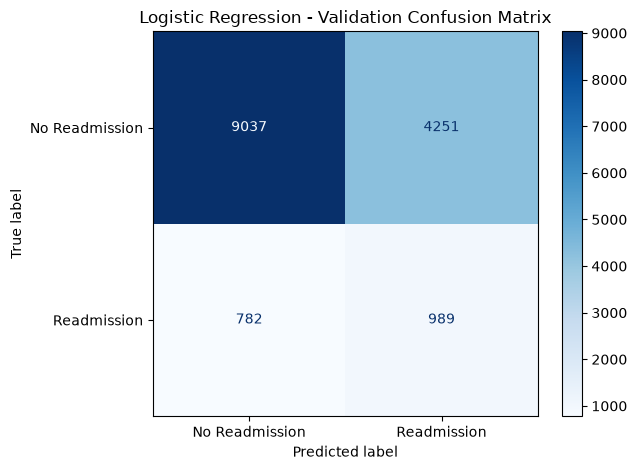


Random Forest
[[10401  2887]
 [  941   830]]


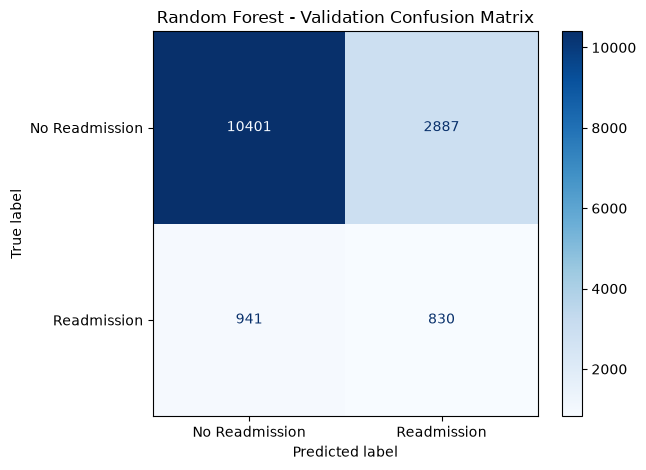


XGBoost
[[9212 4076]
 [ 765 1006]]


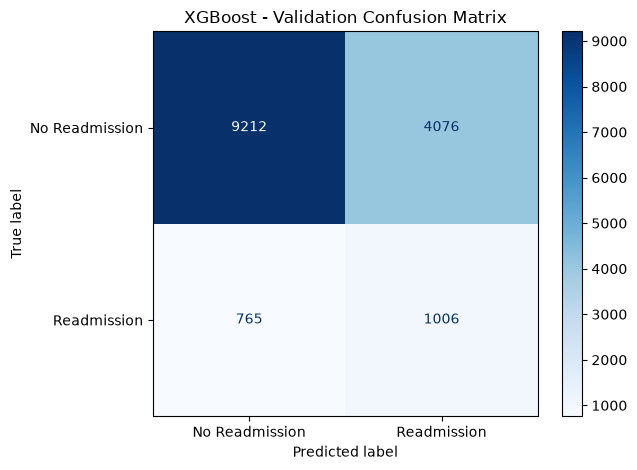

In [50]:
# Cell 51: Confusion matrices

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, result in validation_results.items():

    print(f"\n{name}")

    cm = confusion_matrix(
        y_validation,
        result["predictions"]
    )

    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Readmission", "Readmission"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"{name} - Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [51]:
# Cell 52: Evaluate different classification thresholds

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for name, result in validation_results.items():

    y_prob = result["probabilities"]

    for threshold in thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_validation,
            y_pred,
            labels=[0, 1]
        ).ravel()

        precision = precision_score(
            y_validation, y_pred, zero_division=0
        )

        recall = recall_score(
            y_validation, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_validation, y_pred, zero_division=0
        )

        specificity = tn / (tn + fp)

        threshold_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "Specificity": specificity,
            "False Positives": fp,
            "False Negatives": fn
        })

threshold_df = pd.DataFrame(threshold_results)

print("Threshold evaluation completed.")
print("Total evaluations:", len(threshold_df))

Threshold evaluation completed.
Total evaluations: 51


In [52]:
# Cell 53: Best threshold based on F1-score

best_thresholds = (
    threshold_df
    .sort_values(
        ["Model", "F1-Score", "Threshold"],
        ascending=[True, False, True]
    )
    .groupby("Model")
    .head(1)
    .reset_index(drop=True)
)

print(
    best_thresholds[
        [
            "Model",
            "Threshold",
            "Precision",
            "Recall",
            "F1-Score",
            "Specificity",
            "False Positives",
            "False Negatives"
        ]
    ].round(4).to_string(index=False)
)

              Model  Threshold  Precision  Recall  F1-Score  Specificity  False Positives  False Negatives
Logistic Regression       0.55     0.2089  0.4461    0.2846       0.7749             2991              981
      Random Forest       0.50     0.2233  0.4687    0.3025       0.7827             2887              941
            XGBoost       0.55     0.2266  0.4404    0.2993       0.7997             2662              991


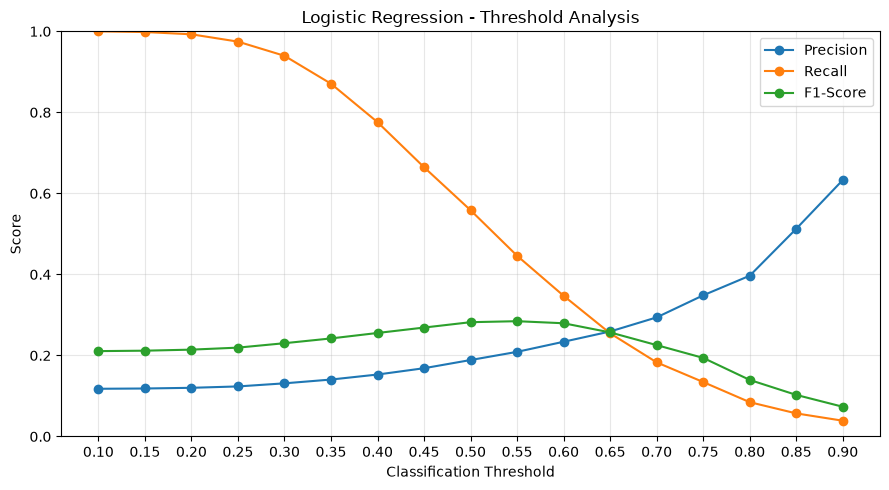

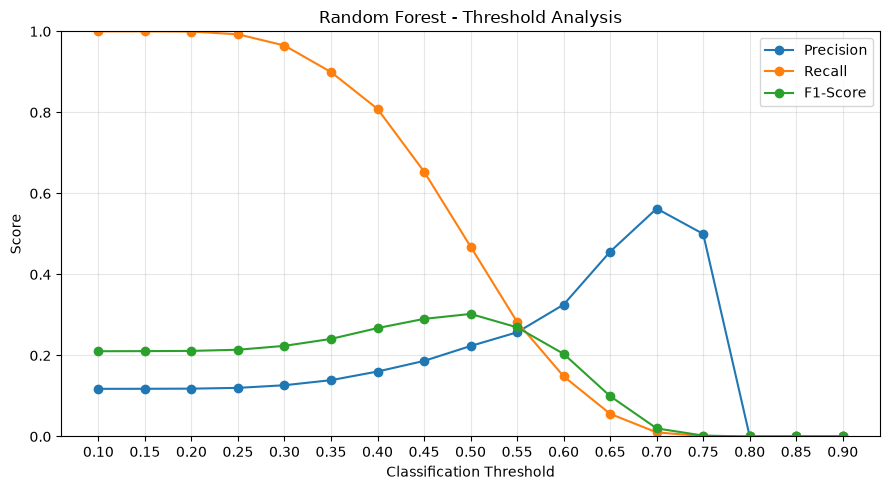

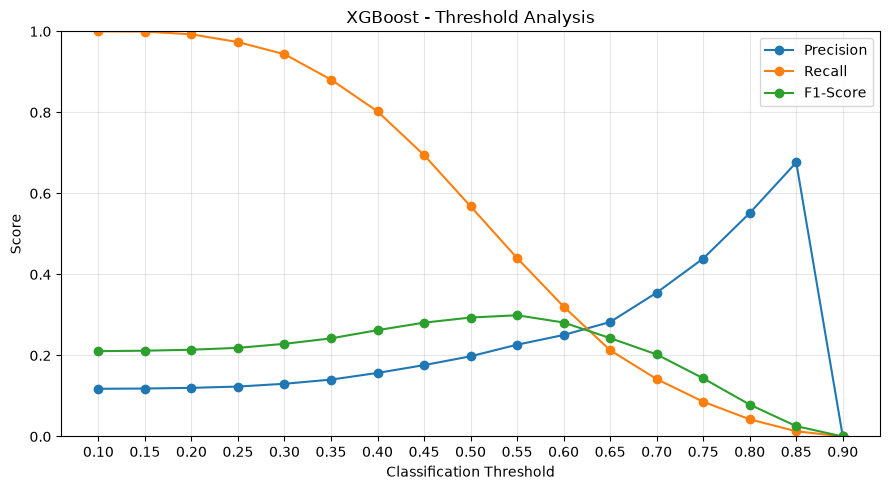

In [53]:
# Cell 54: Visualise threshold performance

import matplotlib.pyplot as plt

metrics_to_plot = ["Precision", "Recall", "F1-Score"]

for model_name in threshold_df["Model"].unique():

    model_data = threshold_df[
        threshold_df["Model"] == model_name
    ]

    plt.figure(figsize=(9, 5))

    for metric in metrics_to_plot:
        plt.plot(
            model_data["Threshold"],
            model_data[metric],
            marker="o",
            label=metric
        )

    plt.title(f"{model_name} - Threshold Analysis")
    plt.xlabel("Classification Threshold")
    plt.ylabel("Score")
    plt.xticks(thresholds)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [54]:
# Cell 55: Identify recall-focused thresholds

recall_focused = threshold_df[
    threshold_df["Recall"] >= 0.60
].copy()

if recall_focused.empty:
    print("No evaluated threshold achieved 60% recall.")
else:
    recall_focused_best = (
        recall_focused
        .sort_values(
            ["Model", "Precision"],
            ascending=[True, False]
        )
        .groupby("Model")
        .head(1)
        .reset_index(drop=True)
    )

    print(
        recall_focused_best[
            [
                "Model",
                "Threshold",
                "Precision",
                "Recall",
                "F1-Score",
                "Specificity",
                "False Positives",
                "False Negatives"
            ]
        ].round(4).to_string(index=False)
    )

              Model  Threshold  Precision  Recall  F1-Score  Specificity  False Positives  False Negatives
Logistic Regression       0.45     0.1685  0.6646    0.2689        0.563             5807              594
      Random Forest       0.45     0.1866  0.6539    0.2903        0.620             5049              613
            XGBoost       0.45     0.1761  0.6945    0.2810        0.567             5754              541


In [55]:
# Cell 56: Group-aware cross-validation

from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Group-aware cross-validation prepared.")
print("Number of folds:", cv.get_n_splits())
print("Training records:", len(X_train))
print("Unique training patients:", groups_train.nunique())

Group-aware cross-validation prepared.
Number of folds: 3
Training records: 70055
Unique training patients: 49307


In [56]:
# Cell 57: Random Forest hyperparameter tuning

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_parameters = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_split": [5, 10, 20],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": ["sqrt", 0.5]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_parameters,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

rf_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("\nBest Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation PR-AUC:")
print(rf_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best Random Forest parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 20, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': None}

Best cross-validation PR-AUC:
0.21976446211826972


In [57]:
# Cell 58: XGBoost hyperparameter tuning

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", xgb.XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        scale_pos_weight=scale_pos_weight,
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

xgb_parameters = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9],
    "model__colsample_bytree": [0.7, 0.8, 0.9],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [1, 5, 10]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameters,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

xgb_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("\nBest XGBoost parameters:")
print(xgb_search.best_params_)

print("\nBest cross-validation PR-AUC:")
print(xgb_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best XGBoost parameters:
{'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.9}

Best cross-validation PR-AUC:
0.22412951350201013


In [58]:
# Cell 59: Generate validation predictions from tuned models

rf_tuned_model = rf_search.best_estimator_
xgb_tuned_model = xgb_search.best_estimator_

tuned_models = {
    "Random Forest Tuned": rf_tuned_model,
    "XGBoost Tuned": xgb_tuned_model
}

tuned_validation_results = {}

for name, model in tuned_models.items():

    predictions = model.predict(X_validation)
    probabilities = model.predict_proba(X_validation)[:, 1]

    tuned_validation_results[name] = {
        "predictions": predictions,
        "probabilities": probabilities
    }

    print(f"{name}: validation predictions generated.")

print("\nOptimised model predictions completed.")

Random Forest Tuned: validation predictions generated.
XGBoost Tuned: validation predictions generated.

Optimised model predictions completed.


In [59]:
# Cell 60: Combined validation comparison

all_validation_results = {
    **validation_results,
    **tuned_validation_results
}

comparison_results = []

for name, result in all_validation_results.items():

    y_pred = result["predictions"]
    y_prob = result["probabilities"]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_validation, y_pred),
        "Precision": precision_score(y_validation, y_pred, zero_division=0),
        "Recall": recall_score(y_validation, y_pred, zero_division=0),
        "F1-Score": f1_score(y_validation, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_validation, y_prob),
        "PR-AUC": average_precision_score(y_validation, y_prob)
    })

comparison_df = pd.DataFrame(comparison_results)

print(
    comparison_df.round(4).to_string(index=False)
)

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression    0.6658     0.1887  0.5584    0.2821   0.6661  0.2349
      Random Forest    0.7458     0.2233  0.4687    0.3025   0.6846  0.2391
            XGBoost    0.6785     0.1980  0.5680    0.2936   0.6795  0.2441
Random Forest Tuned    0.7764     0.2363  0.4037    0.2981   0.6774  0.2417
      XGBoost Tuned    0.6869     0.2025  0.5658    0.2983   0.6835  0.2524



Random Forest Tuned
[[10977  2311]
 [ 1056   715]]


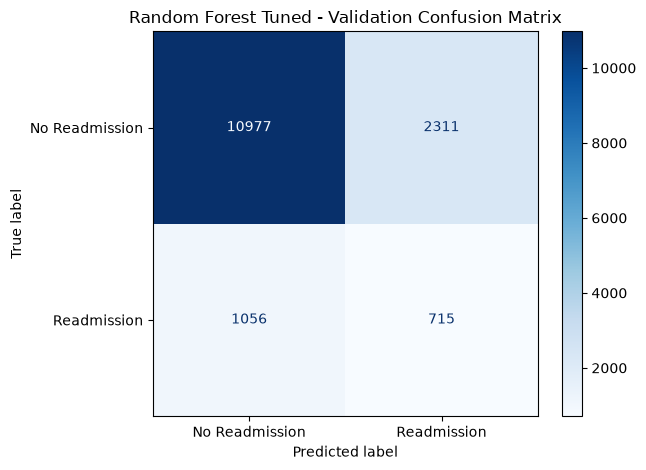


XGBoost Tuned
[[9342 3946]
 [ 769 1002]]


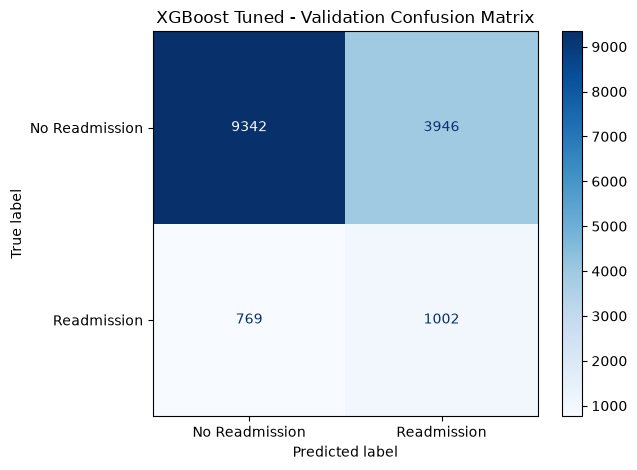

In [60]:
# Cell 61: Confusion matrices for tuned models

for name, result in tuned_validation_results.items():

    print(f"\n{name}")

    cm = confusion_matrix(
        y_validation,
        result["predictions"]
    )

    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Readmission", "Readmission"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"{name} - Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [61]:
# Cell 62: Threshold evaluation for all five models

all_threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for name, result in all_validation_results.items():

    y_prob = result["probabilities"]

    for threshold in thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_validation,
            y_pred,
            labels=[0, 1]
        ).ravel()

        all_threshold_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_validation, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_validation, y_pred, zero_division=0
            ),
            "F1-Score": f1_score(
                y_validation, y_pred, zero_division=0
            ),
            "Specificity": tn / (tn + fp),
            "False Positives": fp,
            "False Negatives": fn
        })

all_threshold_df = pd.DataFrame(all_threshold_results)

print("Total threshold evaluations:", len(all_threshold_df))
print("Models evaluated:", all_threshold_df["Model"].nunique())

Total threshold evaluations: 85
Models evaluated: 5


In [62]:
# Cell 63: Best F1 threshold for all five models

best_thresholds_all = (
    all_threshold_df
    .sort_values(
        ["Model", "F1-Score", "Threshold"],
        ascending=[True, False, True]
    )
    .groupby("Model")
    .head(1)
    .reset_index(drop=True)
)

print(
    best_thresholds_all[
        [
            "Model",
            "Threshold",
            "Precision",
            "Recall",
            "F1-Score",
            "Specificity",
            "False Positives",
            "False Negatives"
        ]
    ].round(4).to_string(index=False)
)

              Model  Threshold  Precision  Recall  F1-Score  Specificity  False Positives  False Negatives
Logistic Regression       0.55     0.2089  0.4461    0.2846       0.7749             2991              981
      Random Forest       0.50     0.2233  0.4687    0.3025       0.7827             2887              941
Random Forest Tuned       0.45     0.2113  0.5082    0.2985       0.7471             3360              871
            XGBoost       0.55     0.2266  0.4404    0.2993       0.7997             2662              991
      XGBoost Tuned       0.55     0.2289  0.4325    0.2993       0.8058             2581             1005


In [63]:
# Cell 64: Best precision at recall >= 60%

recall_candidates = all_threshold_df[
    all_threshold_df["Recall"] >= 0.60
].copy()

if recall_candidates.empty:
    print("No model achieved 60% recall.")
else:
    best_recall_options = (
        recall_candidates
        .sort_values(
            ["Model", "Precision", "Recall"],
            ascending=[True, False, False]
        )
        .groupby("Model")
        .head(1)
        .reset_index(drop=True)
    )

    print(
        best_recall_options[
            [
                "Model",
                "Threshold",
                "Precision",
                "Recall",
                "F1-Score",
                "Specificity",
                "False Positives",
                "False Negatives"
            ]
        ].round(4).to_string(index=False)
    )

              Model  Threshold  Precision  Recall  F1-Score  Specificity  False Positives  False Negatives
Logistic Regression       0.45     0.1685  0.6646    0.2689       0.5630             5807              594
      Random Forest       0.45     0.1866  0.6539    0.2903       0.6200             5049              613
Random Forest Tuned       0.40     0.1900  0.6149    0.2903       0.6506             4643              682
            XGBoost       0.45     0.1761  0.6945    0.2810       0.5670             5754              541
      XGBoost Tuned       0.45     0.1763  0.6900    0.2809       0.5704             5709              549


In [64]:
# Cell 65: Prepare Experiment A using the same patient splits

# Use original diagnosis codes
X_original_eligible = X_original.iloc[eligible_positions].copy()

# Reuse the exact same split indices from Experiment B
X_train_A = X_original_eligible.iloc[train_idx].copy()
X_validation_A = X_original_eligible.iloc[validation_idx].copy()
X_test_A = X_original_eligible.iloc[test_idx].copy()

# Targets remain identical
y_train_A = y_train.copy()
y_validation_A = y_validation.copy()
y_test_A = y_test.copy()

print("Experiment A dataset shapes:")
print("Training:", X_train_A.shape)
print("Validation:", X_validation_A.shape)
print("Testing:", X_test_A.shape)

assert X_train_A.shape[1] == 52
assert X_validation_A.shape[1] == 52
assert X_test_A.shape[1] == 52

assert X_train_A.index.equals(X_train.index)
assert X_validation_A.index.equals(X_validation.index)
assert X_test_A.index.equals(X_test.index)

print("\nExperiment A split verification passed.")

Experiment A dataset shapes:
Training: (70055, 52)
Validation: (15059, 52)
Testing: (15000, 52)

Experiment A split verification passed.


In [65]:
# Cell 66: Identify numerical and categorical features

missing_indicator_features = [
    "diag_1_missing",
    "diag_2_missing",
    "diag_3_missing",
    "payer_code_missing",
    "race_missing",
    "max_glu_serum_missing",
    "A1Cresult_missing",
    "medical_specialty_missing"
]

numerical_features_A = [
    col for col in X_train_A.columns
    if pd.api.types.is_numeric_dtype(X_train_A[col])
    and col not in missing_indicator_features
]

categorical_features_A = [
    col for col in X_train_A.columns
    if col not in numerical_features_A
]

print("Numerical features:", len(numerical_features_A))
print("Categorical features:", len(categorical_features_A))

assert len(numerical_features_A) == 9
assert len(categorical_features_A) == 43

print("\nExperiment A feature classification passed.")

Numerical features: 9
Categorical features: 43

Experiment A feature classification passed.


In [66]:
# Cell 67: Experiment A preprocessing

numerical_transformer_A = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_A = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

preprocessor_A = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_A, numerical_features_A),
        ("cat", categorical_transformer_A, categorical_features_A)
    ],
    remainder="drop"
)

# Fit only on Experiment A training data
X_train_A_processed = preprocessor_A.fit_transform(X_train_A)

X_validation_A_processed = preprocessor_A.transform(X_validation_A)

X_test_A_processed = preprocessor_A.transform(X_test_A)

print("Experiment A preprocessing completed.")

print("Training:", X_train_A_processed.shape)
print("Validation:", X_validation_A_processed.shape)
print("Testing:", X_test_A_processed.shape)

assert X_train_A_processed.shape[1] == X_validation_A_processed.shape[1]
assert X_train_A_processed.shape[1] == X_test_A_processed.shape[1]

print("\nExperiment A preprocessing verified.")

Experiment A preprocessing completed.
Training: (70055, 974)
Validation: (15059, 974)
Testing: (15000, 974)

Experiment A preprocessing verified.


In [67]:
# Cell 68: Experiment A - Logistic Regression

lr_model_A = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    solver="saga",
    C=0.5,
    tol=1e-3,
    random_state=42
)

lr_model_A.fit(X_train_A_processed, y_train_A)

print("Experiment A Logistic Regression completed.")
print("Iterations:", lr_model_A.n_iter_[0])
print(
    "Converged:",
    lr_model_A.n_iter_[0] < lr_model_A.max_iter
)

Experiment A Logistic Regression completed.
Iterations: 352
Converged: True


In [68]:
# Cell 69: Experiment A - Random Forest

rf_model_A = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf_model_A.fit(X_train_A_processed, y_train_A)

print("Experiment A Random Forest completed.")

Experiment A Random Forest completed.


In [69]:
# Cell 70: Experiment A - XGBoost

xgb_model_A = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model_A.fit(X_train_A_processed, y_train_A)

print("Experiment A XGBoost completed.")

Experiment A XGBoost completed.


In [70]:
# Generate Experiment A validation predictions

models_A = {
    "Logistic Regression A": lr_model_A,
    "Random Forest A": rf_model_A,
    "XGBoost A": xgb_model_A
}

validation_results_A = {}

for name, model in models_A.items():

    predictions = model.predict(X_validation_A_processed)

    probabilities = model.predict_proba(
        X_validation_A_processed
    )[:, 1]

    validation_results_A[name] = {
        "predictions": predictions,
        "probabilities": probabilities
    }

    print(f"{name}: predictions generated.")

print("\nExperiment A validation predictions completed.")

Logistic Regression A: predictions generated.
Random Forest A: predictions generated.
XGBoost A: predictions generated.

Experiment A validation predictions completed.


In [71]:
metrics_A = []

for name, result in validation_results_A.items():

    y_pred = result["predictions"]
    y_prob = result["probabilities"]

    metrics_A.append({
        "Model": name,
        "Accuracy": accuracy_score(y_validation_A, y_pred),
        "Precision": precision_score(
            y_validation_A, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_validation_A, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_validation_A, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_validation_A, y_prob),
        "PR-AUC": average_precision_score(y_validation_A, y_prob)
    })

metrics_A_df = pd.DataFrame(metrics_A)

print(metrics_A_df.round(4).to_string(index=False))

                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression A    0.6664     0.1884  0.5551    0.2813   0.6649  0.2356
      Random Forest A    0.7405     0.2192  0.4709    0.2991   0.6839  0.2408
            XGBoost A    0.6807     0.1982  0.5630    0.2931   0.6813  0.2455


In [72]:
# Cell 73: Experiment A vs Experiment B comparison

metrics_B_df = comparison_df[
    comparison_df["Model"].isin([
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ])
].copy()

metrics_A_compare = metrics_A_df.copy()

metrics_A_compare["Model"] = metrics_A_compare["Model"].str.replace(
    " A", "", regex=False
)

metrics_B_compare = metrics_B_df.copy()

comparison_AB = metrics_A_compare.merge(
    metrics_B_compare,
    on="Model",
    suffixes=("_A", "_B")
)

columns_to_show = [
    "Model",
    "Accuracy_A", "Accuracy_B",
    "Precision_A", "Precision_B",
    "Recall_A", "Recall_B",
    "F1-Score_A", "F1-Score_B",
    "ROC-AUC_A", "ROC-AUC_B",
    "PR-AUC_A", "PR-AUC_B"
]

print(comparison_AB[columns_to_show].round(4).to_string(index=False))

              Model  Accuracy_A  Accuracy_B  Precision_A  Precision_B  Recall_A  Recall_B  F1-Score_A  F1-Score_B  ROC-AUC_A  ROC-AUC_B  PR-AUC_A  PR-AUC_B
Logistic Regression      0.6664      0.6658       0.1884       0.1887    0.5551    0.5584      0.2813      0.2821     0.6649     0.6661    0.2356    0.2349
      Random Forest      0.7405      0.7458       0.2192       0.2233    0.4709    0.4687      0.2991      0.3025     0.6839     0.6846    0.2408    0.2391
            XGBoost      0.6807      0.6785       0.1982       0.1980    0.5630    0.5680      0.2931      0.2936     0.6813     0.6795    0.2455    0.2441


In [73]:
# Cell 74: Define final candidate models

final_candidates = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Random Forest Tuned": rf_tuned_model,
    "XGBoost Tuned": xgb_tuned_model
}

print("Final candidate models:")

for name, model in final_candidates.items():
    print("-", name)

print("\nAll candidate models are ready.")

Final candidate models:
- Logistic Regression
- Random Forest
- XGBoost
- Random Forest Tuned
- XGBoost Tuned

All candidate models are ready.


In [74]:
# Cell 75: Define validation-selected thresholds

selected_thresholds = {
    "Logistic Regression": 0.55,
    "Random Forest": 0.50,
    "XGBoost": 0.55,
    "Random Forest Tuned": 0.45,
    "XGBoost Tuned": 0.55
}

print("Selected thresholds:")

for name, threshold in selected_thresholds.items():
    print(f"{name}: {threshold}")

Selected thresholds:
Logistic Regression: 0.55
Random Forest: 0.5
XGBoost: 0.55
Random Forest Tuned: 0.45
XGBoost Tuned: 0.55


In [75]:
# Cell 76: Final test predictions (corrected)

test_results = {}

for name, model in final_candidates.items():

    # Baseline models require preprocessed data
    if name in [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ]:
        X_input = X_test_processed

    # Tuned models are complete pipelines:
    # they perform preprocessing internally
    else:
        X_input = X_test

    # Generate probabilities
    probabilities = model.predict_proba(X_input)[:, 1]

    # Apply validation-selected threshold
    threshold = selected_thresholds[name]

    predictions = (probabilities >= threshold).astype(int)

    test_results[name] = {
        "probabilities": probabilities,
        "predictions": predictions,
        "threshold": threshold
    }

    print(f"{name}: test predictions generated.")

print("\nAll final test predictions completed.")

Logistic Regression: test predictions generated.
Random Forest: test predictions generated.
XGBoost: test predictions generated.
Random Forest Tuned: test predictions generated.
XGBoost Tuned: test predictions generated.

All final test predictions completed.


In [76]:
# Cell 77: Final test evaluation

test_metrics = []

for name, result in test_results.items():

    y_pred = result["predictions"]
    y_prob = result["probabilities"]

    test_metrics.append({
        "Model": name,
        "Threshold": result["threshold"],
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_metrics)

print(test_results_df.round(4).to_string(index=False))

              Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression       0.55    0.7347     0.1909  0.4226    0.2630   0.6522  0.2066
      Random Forest       0.50    0.7395     0.2031  0.4536    0.2806   0.6663  0.2074
            XGBoost       0.55    0.7602     0.2084  0.4077    0.2758   0.6624  0.2128
Random Forest Tuned       0.45    0.7089     0.1824  0.4589    0.2610   0.6513  0.2071
      XGBoost Tuned       0.55    0.7599     0.2063  0.4018    0.2726   0.6610  0.2113


In [77]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [78]:
# Convert the processed training data into a dense DataFrame
X_train_shap = pd.DataFrame(
    X_train_processed.toarray(),
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index
)

# Use a representative sample to keep SHAP computation manageable
X_shap_sample = X_train_shap.sample(
    n=min(1000, len(X_train_shap)),
    random_state=42
)

print("Training data shape:", X_train_shap.shape)
print("SHAP sample shape:", X_shap_sample.shape)
print("Number of encoded features:", X_shap_sample.shape[1])

Training data shape: (70055, 915)
SHAP sample shape: (1000, 915)
Number of encoded features: 915


In [79]:
xgb_explainer = shap.TreeExplainer(xgb_model)

xgb_shap_values = xgb_explainer.shap_values(
    X_shap_sample
)

print("SHAP values shape:", np.array(xgb_shap_values).shape)

SHAP values shape: (1000, 915)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


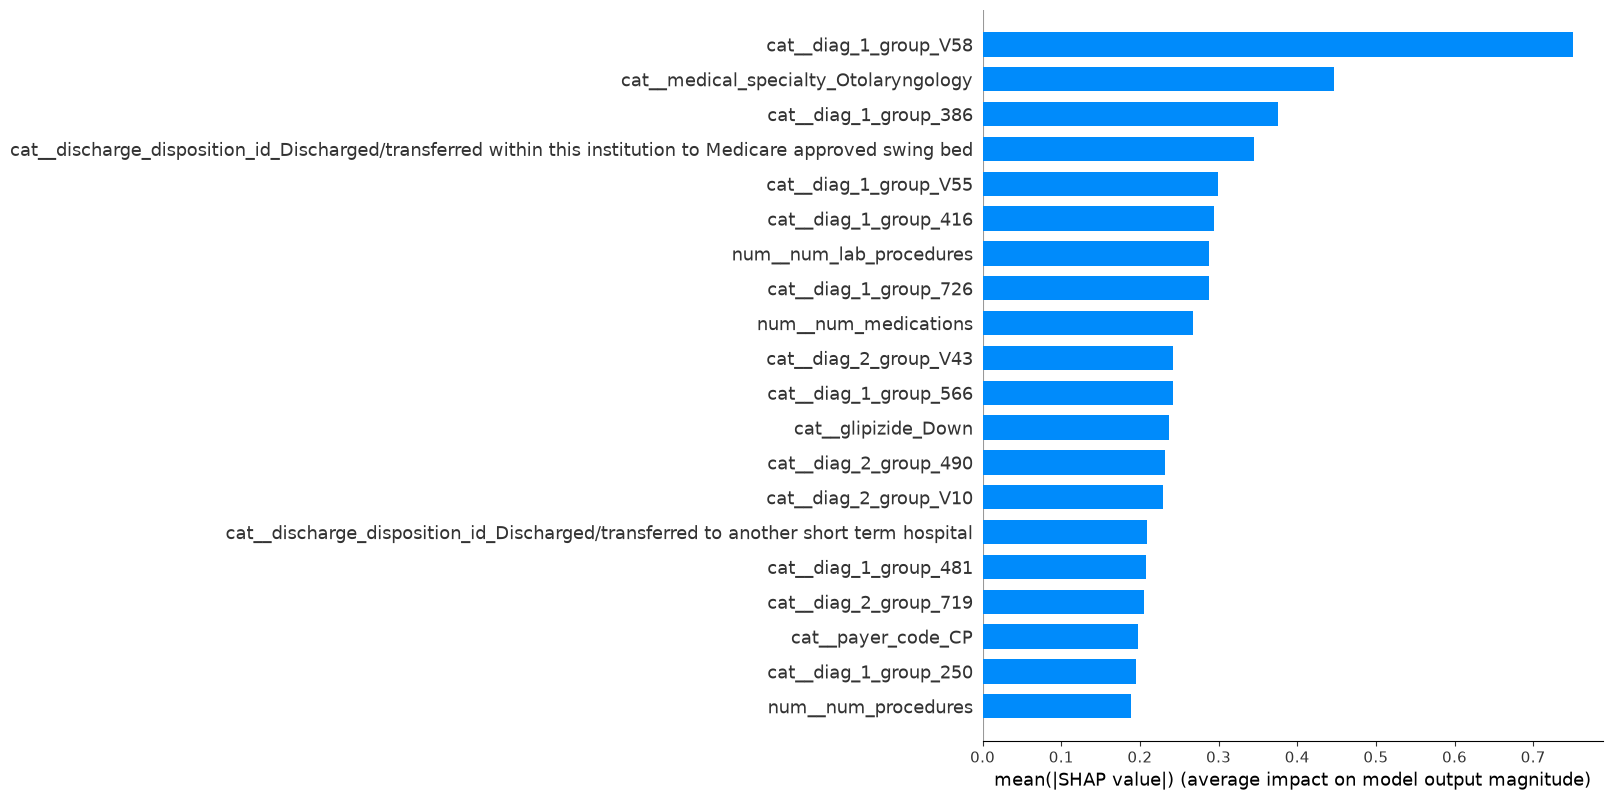

In [80]:
shap.summary_plot(
    xgb_shap_values,
    X_shap_sample,
    plot_type="bar",
    max_display=20
)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


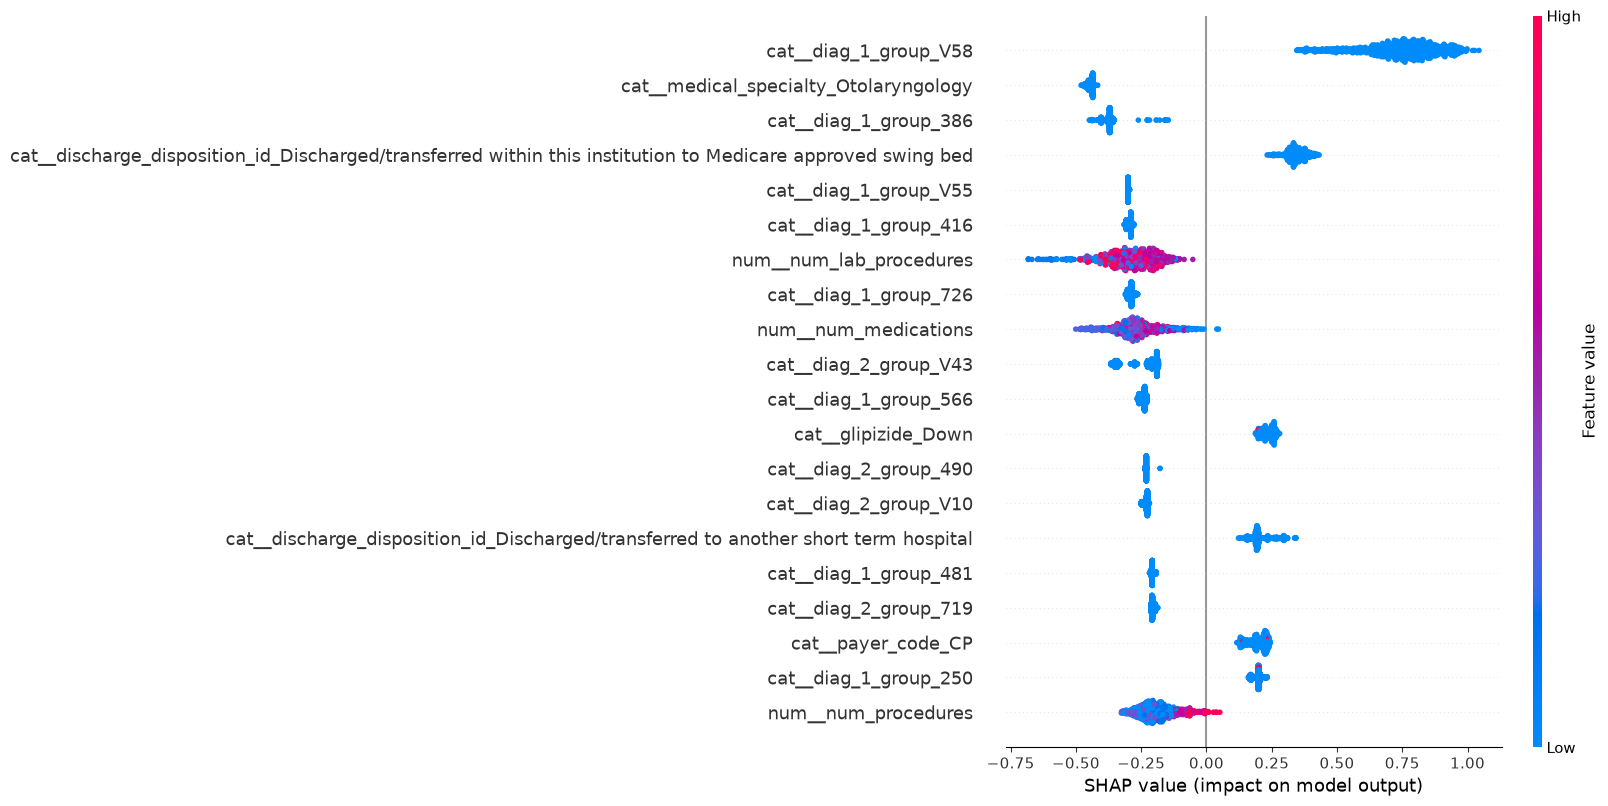

In [81]:
shap.summary_plot(
    xgb_shap_values,
    X_shap_sample,
    max_display=20
)

In [82]:
# Mean absolute SHAP importance
shap_importance = np.abs(xgb_shap_values).mean(axis=0)

# Frequency of non-zero values in the SHAP sample
feature_frequency = (X_shap_sample != 0).sum(axis=0)

feature_analysis = pd.DataFrame({
    "Feature": X_shap_sample.columns,
    "Mean_Abs_SHAP": shap_importance,
    "Occurrences": feature_frequency.values,
    "Occurrence_Percentage": (
        feature_frequency.values / len(X_shap_sample) * 100
    )
})

feature_analysis = feature_analysis.sort_values(
    "Mean_Abs_SHAP", ascending=False
)

print(feature_analysis.head(20).round(4).to_string(index=False))

                                                                                                    Feature  Mean_Abs_SHAP  Occurrences  Occurrence_Percentage
                                                                                      cat__diag_1_group_V58         0.7507            0                    0.0
                                                                      cat__medical_specialty_Otolaryngology         0.4473            0                    0.0
                                                                                      cat__diag_1_group_386         0.3756            1                    0.1
cat__discharge_disposition_id_Discharged/transferred within this institution to Medicare approved swing bed         0.3445            2                    0.2
                                                                                      cat__diag_1_group_V55         0.2998            0                    0.0
                                              

In [83]:
# Get the actual labels for the sampled training encounters
sample_labels = y_train.loc[X_shap_sample.index]

# Select one positive and one negative encounter
positive_indices = sample_labels[sample_labels == 1].index
negative_indices = sample_labels[sample_labels == 0].index

positive_idx = positive_indices[0]
negative_idx = negative_indices[0]

print("Positive encounter index:", positive_idx)
print("Negative encounter index:", negative_idx)

print("Positive actual label:", sample_labels.loc[positive_idx])
print("Negative actual label:", sample_labels.loc[negative_idx])

Positive encounter index: 13521
Negative encounter index: 58383
Positive actual label: 1
Negative actual label: 0


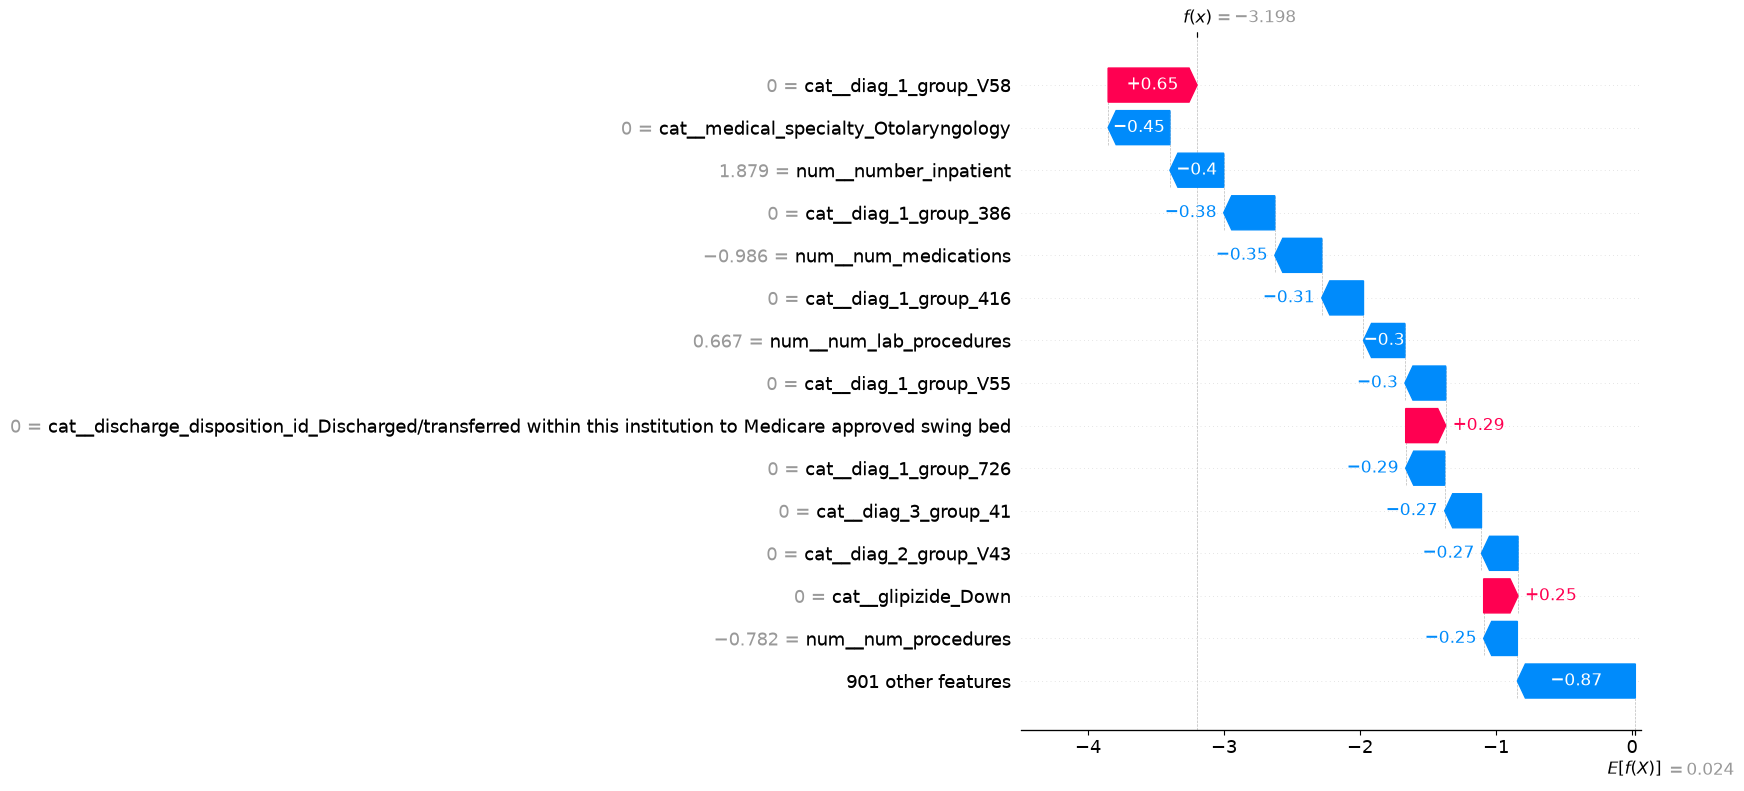

In [84]:
positive_explanation = xgb_explainer(
    X_shap_sample.loc[[positive_idx]]
)

shap.plots.waterfall(
    positive_explanation[0],
    max_display=15
)

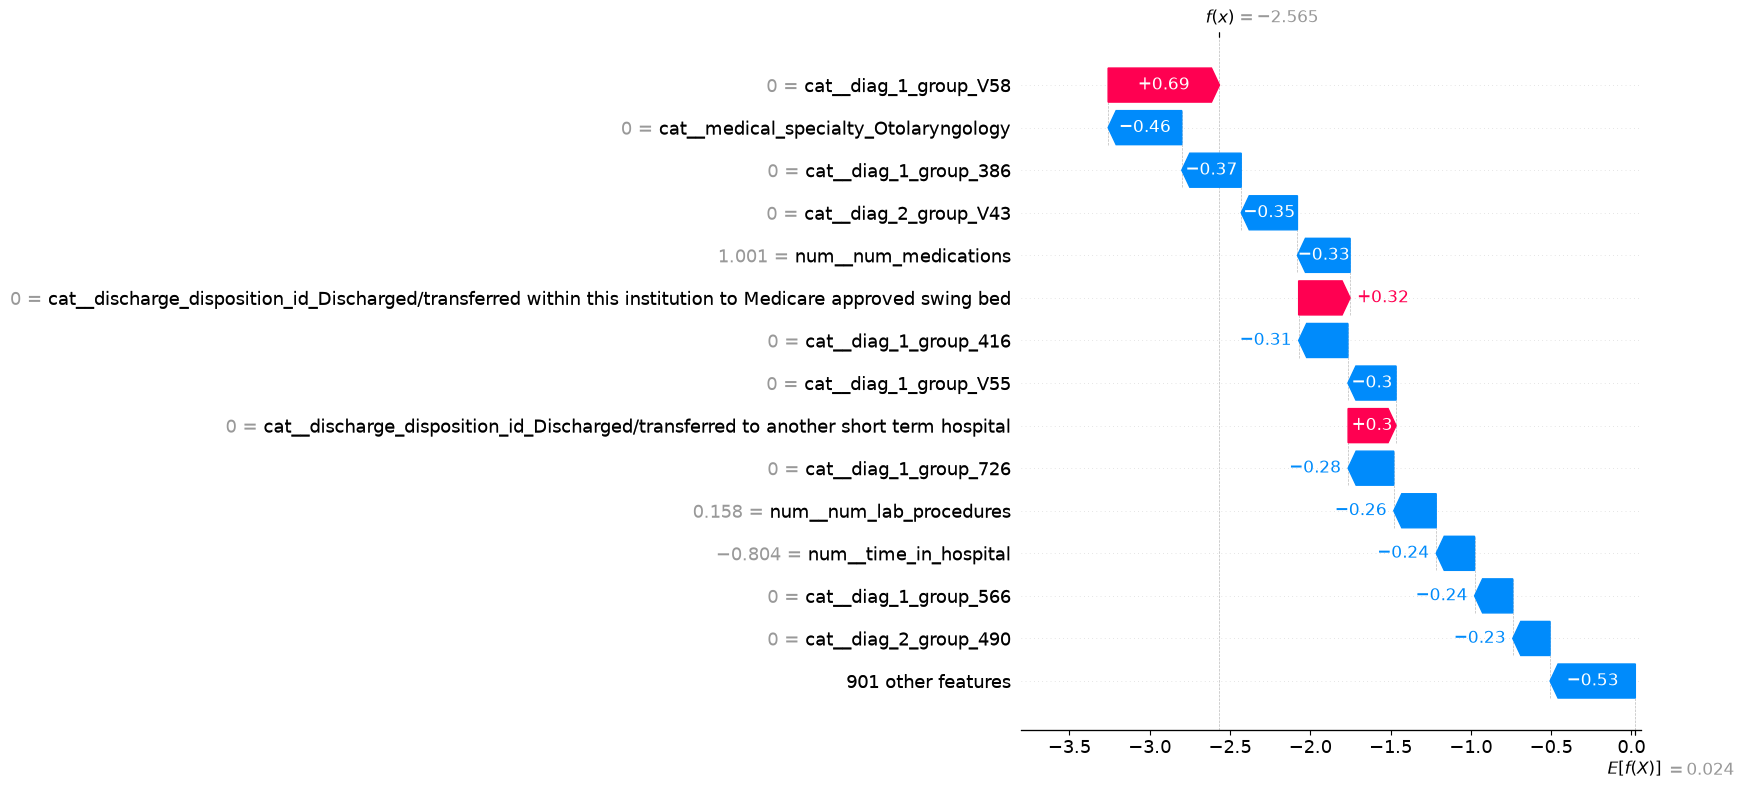

In [85]:
negative_explanation = xgb_explainer(
    X_shap_sample.loc[[negative_idx]]
)

shap.plots.waterfall(
    negative_explanation[0],
    max_display=15
)

In [86]:
# Recover the exact row positions used in the SHAP sample
sample_positions = X_train.index.get_indexer(X_shap_sample.index)

# Extract the same rows from the original sparse training matrix
X_sparse_sample = X_train_processed[sample_positions]

# Compare predictions using sparse and dense inputs
sparse_probabilities = xgb_model.predict_proba(
    X_sparse_sample
)[:, 1]

dense_probabilities = xgb_model.predict_proba(
    X_shap_sample
)[:, 1]

print("Maximum probability difference:",
      np.max(np.abs(sparse_probabilities - dense_probabilities)))

print("Mean probability difference:",
      np.mean(np.abs(sparse_probabilities - dense_probabilities)))

print("\nFirst 10 predictions:")
print(pd.DataFrame({
    "Sparse prediction": sparse_probabilities[:10],
    "Dense prediction": dense_probabilities[:10]
}).round(5))

Maximum probability difference: 0.8273314
Mean probability difference: 0.34479553

First 10 predictions:
   Sparse prediction  Dense prediction
0            0.48963           0.07140
1            0.30920           0.09651
2            0.45215           0.27674
3            0.62978           0.01664
4            0.69903           0.03924
5            0.56888           0.07736
6            0.51102           0.10572
7            0.22006           0.26956
8            0.26260           0.12248
9            0.20664           0.07644


In [87]:
# Raw model outputs (log-odds)
sparse_raw_output = xgb_model.predict(
    X_sparse_sample,
    output_margin=True
)

dense_raw_output = xgb_model.predict(
    X_shap_sample,
    output_margin=True
)

# Reconstruct raw outputs from the existing dense SHAP values
shap_reconstructed_output = (
    xgb_explainer.expected_value
    + np.sum(xgb_shap_values, axis=1)
)

print("Sparse vs dense raw-output difference:",
      np.max(np.abs(sparse_raw_output - dense_raw_output)))

print("Dense prediction vs SHAP reconstruction difference:",
      np.max(np.abs(dense_raw_output - shap_reconstructed_output)))

Sparse vs dense raw-output difference: 6.742964
Dense prediction vs SHAP reconstruction difference: 2.3841858e-06


In [88]:
# Use the original sparse training matrix
X_sparse_shap = X_sparse_sample

# Create the TreeExplainer with the existing XGBoost model
xgb_explainer_sparse = shap.TreeExplainer(xgb_model)

# Calculate SHAP values using sparse input
xgb_shap_values_sparse = xgb_explainer_sparse.shap_values(
    X_sparse_shap
)

print("SHAP values shape:",
      np.array(xgb_shap_values_sparse).shape)

SHAP values shape: (1000, 915)


In [89]:
# Actual XGBoost raw outputs for sparse input
sparse_raw_output = xgb_model.predict(
    X_sparse_shap,
    output_margin=True
)

# Reconstructed outputs from SHAP
sparse_shap_reconstructed = (
    xgb_explainer_sparse.expected_value
    + np.sum(xgb_shap_values_sparse, axis=1)
)

print(
    "Maximum SHAP reconstruction error:",
    np.max(np.abs(
        sparse_raw_output - sparse_shap_reconstructed
    ))
)

Maximum SHAP reconstruction error: 1.0728836e-06


In [90]:
X_sparse_shap_dense = pd.DataFrame(
    X_sparse_shap.toarray(),
    columns=preprocessor.get_feature_names_out(),
    index=X_shap_sample.index
)

print("Plotting data shape:", X_sparse_shap_dense.shape)

Plotting data shape: (1000, 915)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


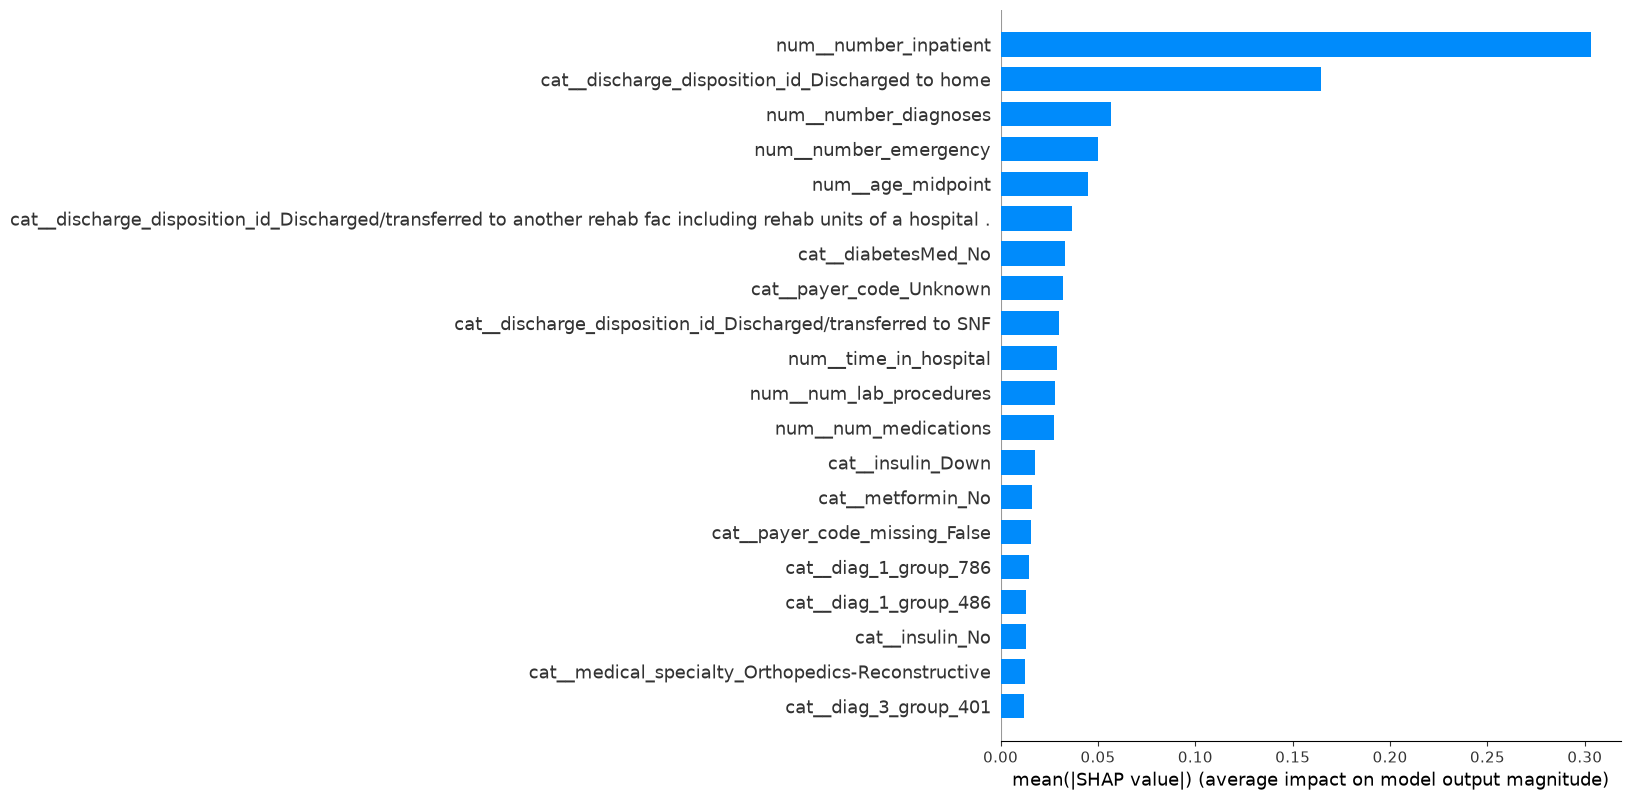

In [91]:
shap.summary_plot(
    xgb_shap_values_sparse,
    X_sparse_shap_dense,
    plot_type="bar",
    max_display=20
)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


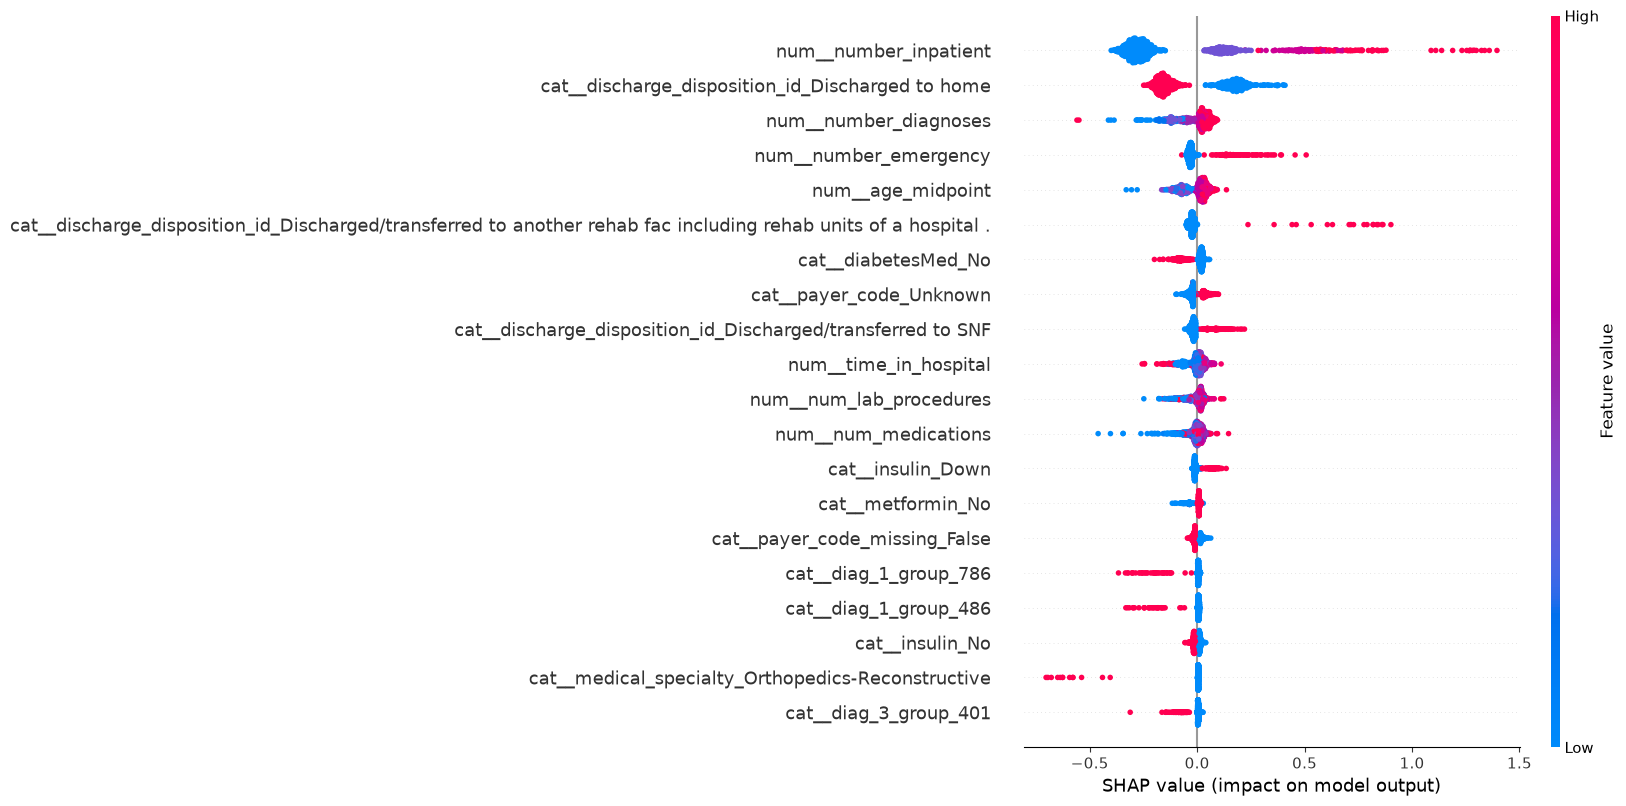

In [92]:
shap.summary_plot(
    xgb_shap_values_sparse,
    X_sparse_shap_dense,
    max_display=20
)

In [93]:
sample_labels = y_train.loc[X_sparse_shap_dense.index]

positive_indices = sample_labels[sample_labels == 1].index
negative_indices = sample_labels[sample_labels == 0].index

positive_idx = positive_indices[0]
negative_idx = negative_indices[0]

print("Positive encounter:", positive_idx)
print("Negative encounter:", negative_idx)

Positive encounter: 13521
Negative encounter: 58383


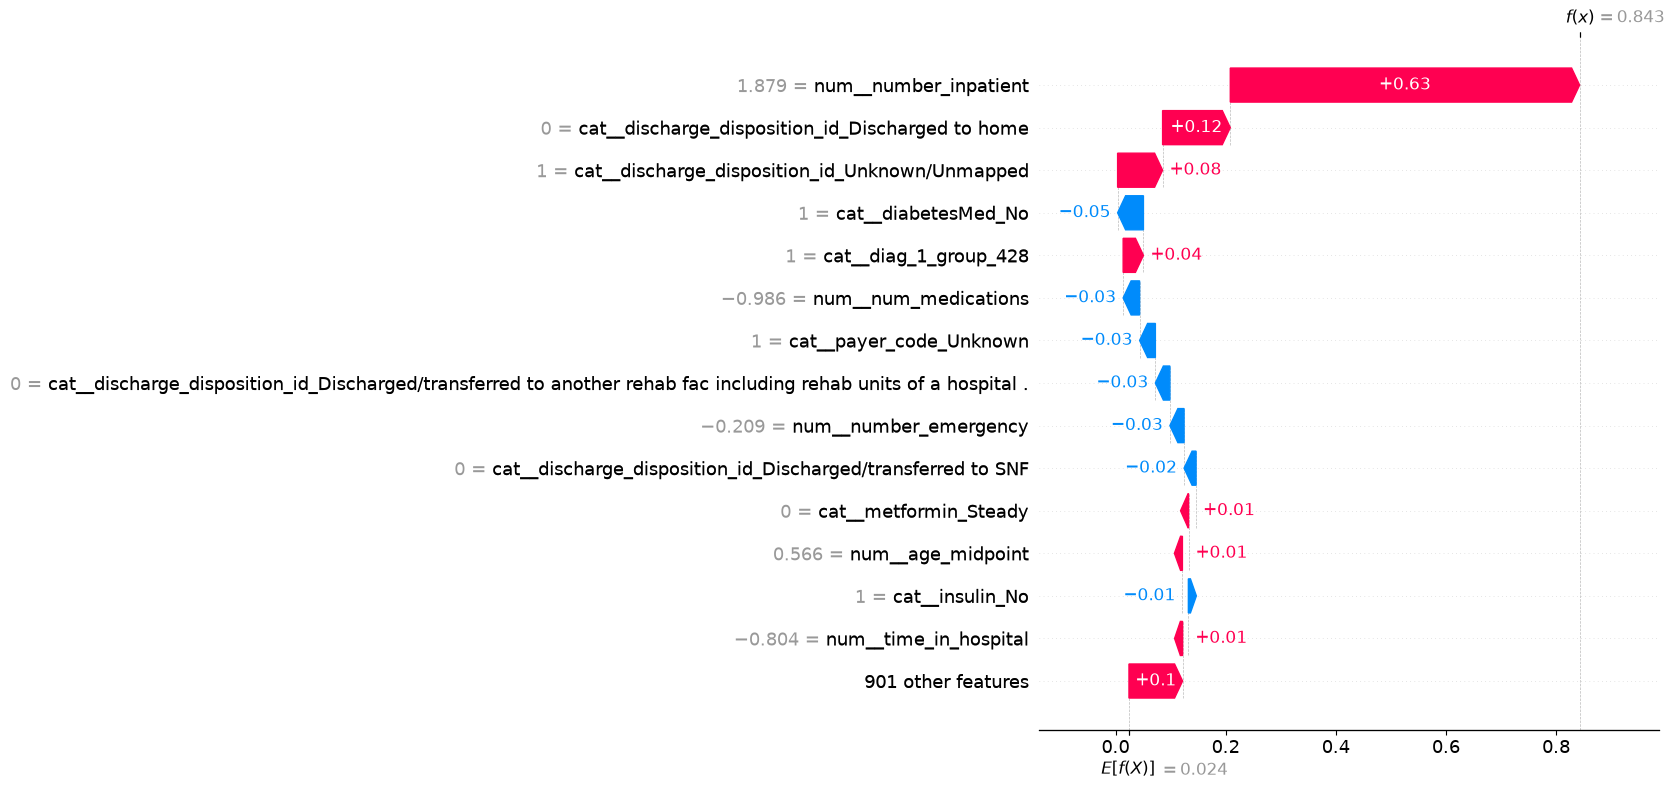

In [94]:
positive_position = X_sparse_shap_dense.index.get_loc(positive_idx)

positive_explanation = shap.Explanation(
    values=xgb_shap_values_sparse[positive_position],
    base_values=xgb_explainer_sparse.expected_value,
    data=X_sparse_shap_dense.loc[positive_idx].values,
    feature_names=X_sparse_shap_dense.columns.tolist()
)

shap.plots.waterfall(
    positive_explanation,
    max_display=15
)

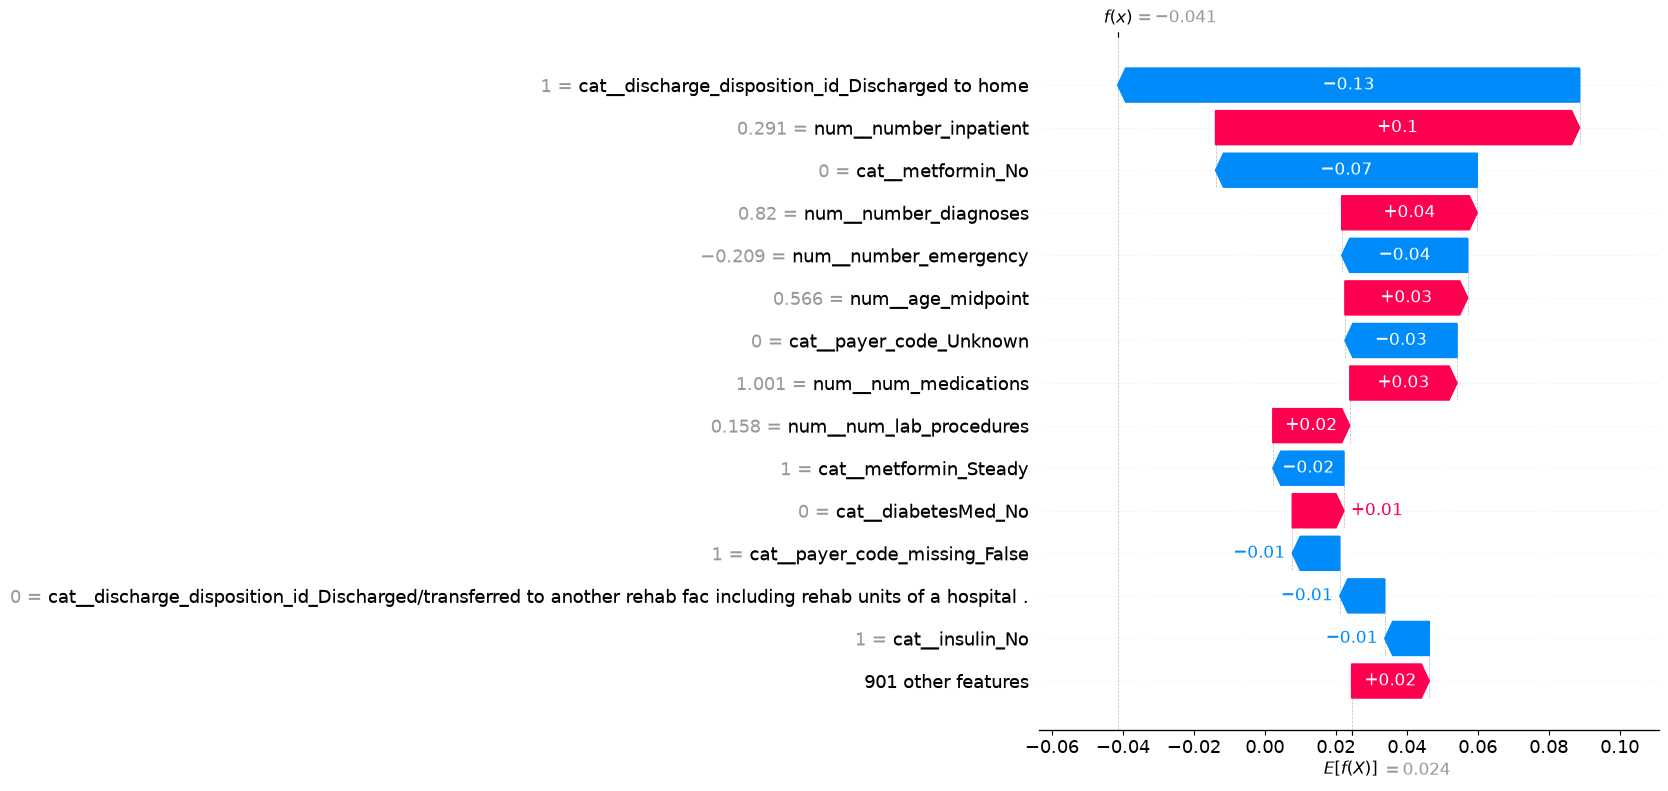

In [95]:
negative_position = X_sparse_shap_dense.index.get_loc(negative_idx)

negative_explanation = shap.Explanation(
    values=xgb_shap_values_sparse[negative_position],
    base_values=xgb_explainer_sparse.expected_value,
    data=X_sparse_shap_dense.loc[negative_idx].values,
    feature_names=X_sparse_shap_dense.columns.tolist()
)

shap.plots.waterfall(
    negative_explanation,
    max_display=15
)

In [96]:
selected_positions = [
    X_train.index.get_loc(positive_idx),
    X_train.index.get_loc(negative_idx)
]

selected_sparse = X_train_processed[selected_positions]

selected_probabilities = xgb_model.predict_proba(
    selected_sparse
)[:, 1]

individual_results = pd.DataFrame({
    "Encounter": [positive_idx, negative_idx],
    "Actual_Label": [
        y_train.loc[positive_idx],
        y_train.loc[negative_idx]
    ],
    "Predicted_Probability": selected_probabilities,
    "Threshold": [0.55, 0.55],
    "Predicted_Label": (
        selected_probabilities >= 0.55
    ).astype(int)
})

print(individual_results.round(4).to_string(index=False))

 Encounter  Actual_Label  Predicted_Probability  Threshold  Predicted_Label
     13521             1                 0.6990       0.55                1
     58383             0                 0.4896       0.55                0


In [97]:
X_rf_shap = X_sparse_shap.toarray().astype(np.float32)

print("Shape:", X_rf_shap.shape)
print("Data type:", X_rf_shap.dtype)
print("Contains NaN:", np.isnan(X_rf_shap).any())

Shape: (1000, 915)
Data type: float32
Contains NaN: False


In [98]:
rf_sparse_prob = rf_model.predict_proba(
    X_sparse_shap
)[:, 1]

rf_dense_prob = rf_model.predict_proba(
    X_rf_shap
)[:, 1]

print(
    "Maximum probability difference:",
    np.max(np.abs(rf_sparse_prob - rf_dense_prob))
)

print(
    "Mean probability difference:",
    np.mean(np.abs(rf_sparse_prob - rf_dense_prob))
)

Maximum probability difference: 3.3306690738754696e-16
Mean probability difference: 5.279110482092619e-17


In [99]:
# Small background sample from the same training distribution
X_rf_background = X_rf_shap[:100]

print("Background shape:", X_rf_background.shape)
print("Explanation sample shape:", X_rf_shap.shape)

Background shape: (100, 915)
Explanation sample shape: (1000, 915)


In [100]:
rf_explainer_interventional = shap.TreeExplainer(
    rf_model,
    data=X_rf_background,
    feature_perturbation="interventional",
    model_output="probability"
)

print("Expected value:",
      rf_explainer_interventional.expected_value)

print("Model output:",
      rf_explainer_interventional.model.model_output)

Expected value: [0.57056489 0.42943511]
Model output: probability


In [101]:
X_rf_test_small = X_rf_shap[:20]

rf_shap_test = rf_explainer_interventional.shap_values(
    X_rf_test_small
)

print("SHAP output type:", type(rf_shap_test))

if isinstance(rf_shap_test, list):
    print("Class 0 shape:", rf_shap_test[0].shape)
    print("Class 1 shape:", rf_shap_test[1].shape)
else:
    print("SHAP shape:", np.array(rf_shap_test).shape)

SHAP output type: <class 'numpy.ndarray'>
SHAP shape: (20, 915, 2)


In [102]:
# Extract class 1 SHAP values
rf_shap_positive = rf_shap_test[:, :, 1]

print("Positive-class SHAP shape:",
      rf_shap_positive.shape)

Positive-class SHAP shape: (20, 915)


In [103]:
rf_expected_positive = (
    rf_explainer_interventional.expected_value[1]
)

rf_reconstructed_prob = (
    rf_expected_positive
    + rf_shap_positive.sum(axis=1)
)

rf_actual_prob = rf_model.predict_proba(
    X_rf_test_small
)[:, 1]

rf_validation = pd.DataFrame({
    "Actual_Probability": rf_actual_prob,
    "SHAP_Reconstructed": rf_reconstructed_prob,
    "Absolute_Error": np.abs(
        rf_actual_prob - rf_reconstructed_prob
    )
})

print(rf_validation.round(7).to_string(index=False))

print(
    "\nMaximum reconstruction error:",
    np.max(rf_validation["Absolute_Error"])
)

 Actual_Probability  SHAP_Reconstructed  Absolute_Error
           0.435020            0.435030         0.00001
           0.275959            0.275968         0.00001
           0.362531            0.362541         0.00001
           0.570475            0.570485         0.00001
           0.628682            0.628692         0.00001
           0.535336            0.535346         0.00001
           0.441407            0.441417         0.00001
           0.251893            0.251902         0.00001
           0.282675            0.282685         0.00001
           0.227956            0.227965         0.00001
           0.445290            0.445300         0.00001
           0.606525            0.606534         0.00001
           0.251508            0.251518         0.00001
           0.400948            0.400958         0.00001
           0.277212            0.277222         0.00001
           0.387940            0.387950         0.00001
           0.343868            0.343878         

In [104]:
X_rf_plot = pd.DataFrame(
    X_rf_test_small,
    columns=preprocessor.get_feature_names_out()
)

print("Plotting data shape:", X_rf_plot.shape)

Plotting data shape: (20, 915)


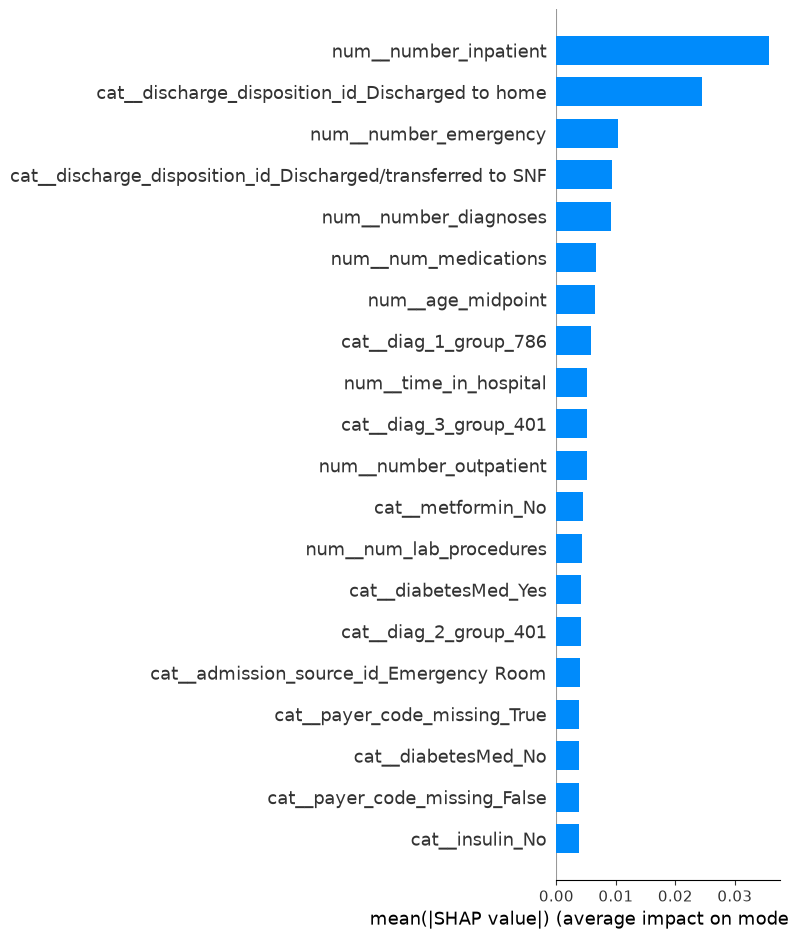

In [105]:
shap.summary_plot(
    rf_shap_positive,
    X_rf_plot,
    plot_type="bar",
    max_display=20
)

In [106]:
# Select 500 encounters from the training sample
X_rf_shap_final = X_rf_shap[:500]

# Calculate SHAP values using the validated interventional explainer
rf_shap_final_all = rf_explainer_interventional.shap_values(
    X_rf_shap_final
)

# Extract class 1 (30-day readmission)
rf_shap_final = rf_shap_final_all[:, :, 1]

print("SHAP values shape:", rf_shap_final.shape)

 99%|===================| 991/1000 [01:41<00:00]        

SHAP values shape: (500, 915)


In [107]:
rf_final_expected = rf_explainer_interventional.expected_value[1]

rf_final_reconstructed = (
    rf_final_expected + rf_shap_final.sum(axis=1)
)

rf_final_probabilities = rf_model.predict_proba(
    X_rf_shap_final
)[:, 1]

rf_final_errors = np.abs(
    rf_final_probabilities - rf_final_reconstructed
)

print("Maximum reconstruction error:",
      rf_final_errors.max())

print("Mean reconstruction error:",
      rf_final_errors.mean())

Maximum reconstruction error: 0.003618165583427535
Mean reconstruction error: 3.8664284399376466e-05


In [108]:
X_rf_plot_final = pd.DataFrame(
    X_rf_shap_final,
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index[:500]
)

print("Plotting data shape:", X_rf_plot_final.shape)

Plotting data shape: (500, 915)


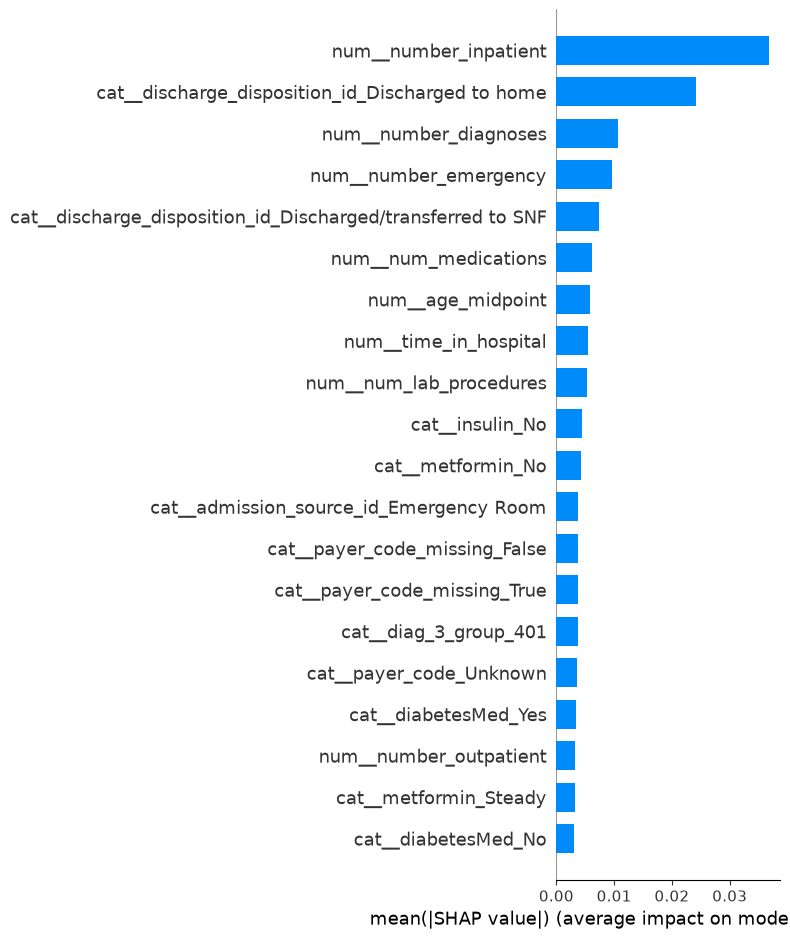

In [109]:
shap.summary_plot(
    rf_shap_final,
    X_rf_plot_final,
    plot_type="bar",
    max_display=20
)

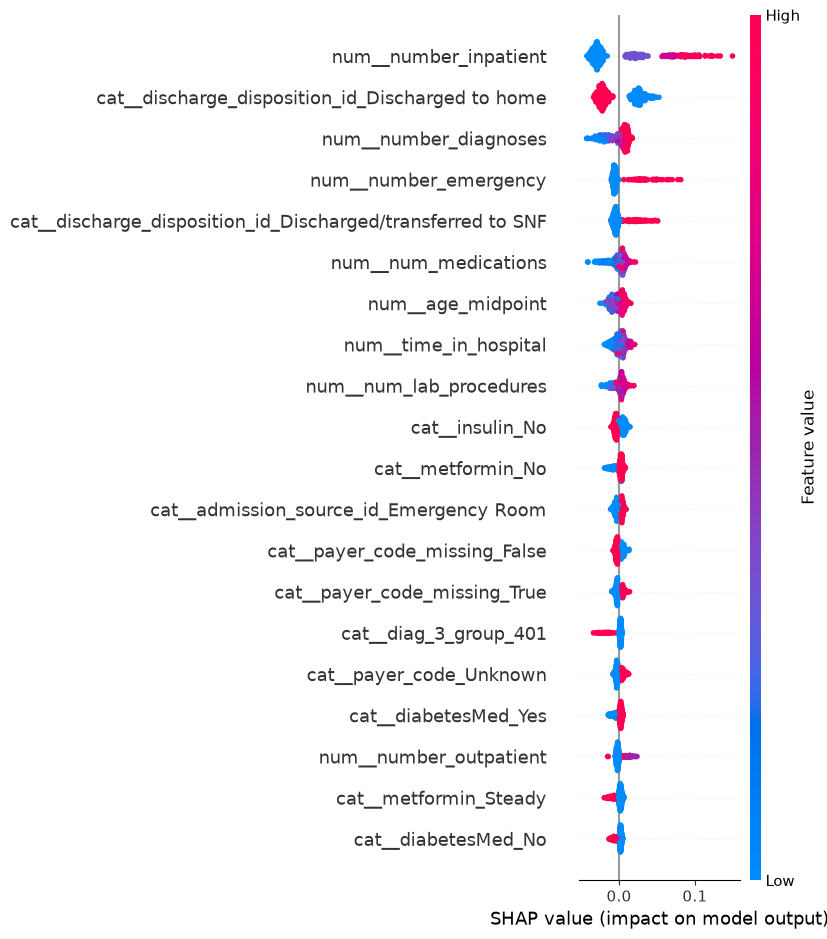

In [110]:
shap.summary_plot(
    rf_shap_final,
    X_rf_plot_final,
    max_display=20
)

In [111]:
rf_error_analysis = pd.DataFrame({
    "Encounter_Index": X_train.index[:500],
    "Actual_Probability": rf_final_probabilities,
    "Reconstructed_Probability": rf_final_reconstructed,
    "Absolute_Error": rf_final_errors
})

print(
    rf_error_analysis.sort_values(
        "Absolute_Error", ascending=False
    ).head(10).round(7).to_string(index=False)
)

 Encounter_Index  Actual_Probability  Reconstructed_Probability  Absolute_Error
             683            0.308562                   0.304944        0.003618
             532            0.277645                   0.279877        0.002232
             457            0.346278                   0.348488        0.002210
             271            0.420981                   0.419194        0.001787
             384            0.492248                   0.490920        0.001328
             436            0.407122                   0.406127        0.000996
              72            0.479027                   0.478053        0.000974
             292            0.237225                   0.238028        0.000803
             641            0.499864                   0.499312        0.000552
             710            0.661245                   0.661255        0.000010


In [114]:
# Actual labels corresponding to the 500 SHAP encounters
rf_sample_labels = y_train.loc[X_rf_plot_final.index]

# Select one positive and one negative encounter within this sample
rf_positive_idx = rf_sample_labels[
    rf_sample_labels == 1
].index[0]

rf_negative_idx = rf_sample_labels[
    rf_sample_labels == 0
].index[0]

print("RF positive encounter:", rf_positive_idx)
print("RF negative encounter:", rf_negative_idx)

print("Positive actual label:",
      rf_sample_labels.loc[rf_positive_idx])

print("Negative actual label:",
      rf_sample_labels.loc[rf_negative_idx])

RF positive encounter: 11
RF negative encounter: 1
Positive actual label: 1
Negative actual label: 0


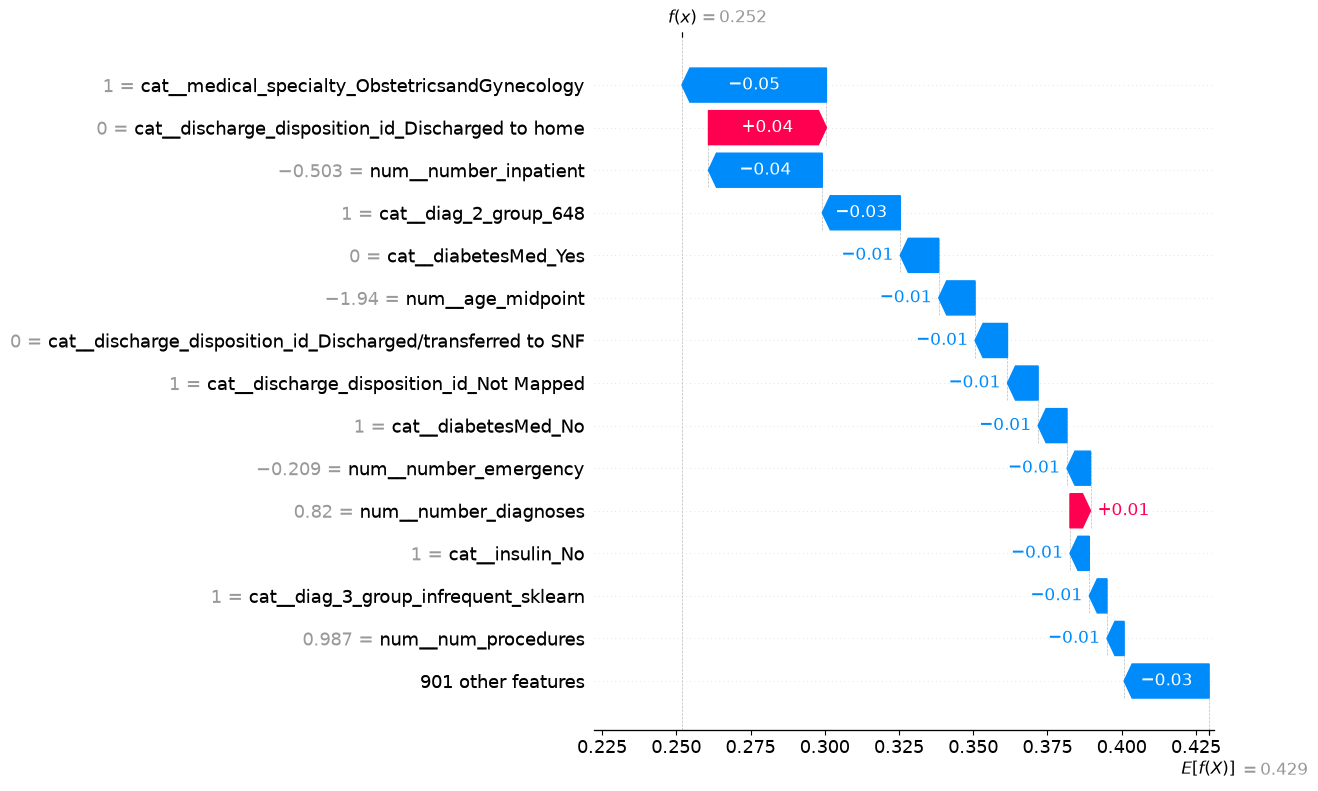

In [115]:
positive_position_rf = X_rf_plot_final.index.get_loc(
    rf_positive_idx
)

rf_positive_explanation = shap.Explanation(
    values=rf_shap_final[positive_position_rf],
    base_values=rf_expected_positive,
    data=X_rf_plot_final.iloc[positive_position_rf].values,
    feature_names=X_rf_plot_final.columns.tolist()
)

shap.plots.waterfall(
    rf_positive_explanation,
    max_display=15
)

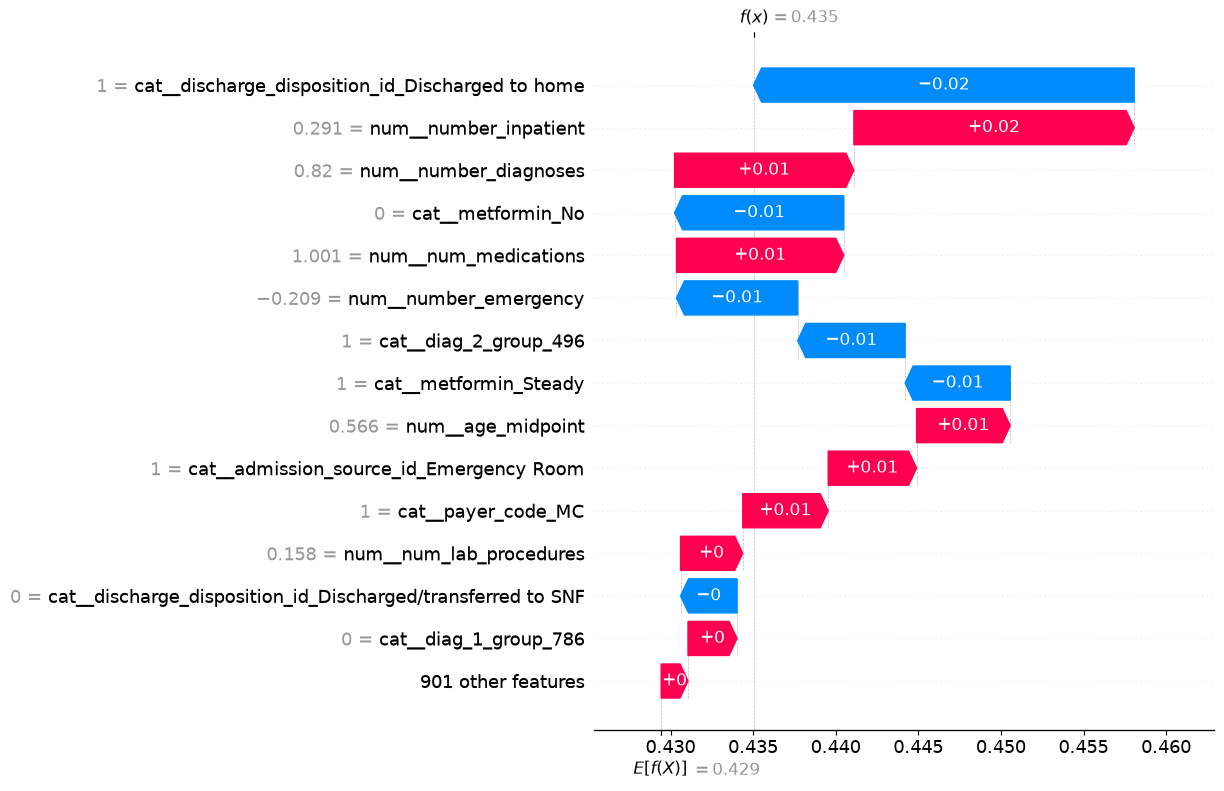

In [116]:
negative_position_rf = X_rf_plot_final.index.get_loc(
    rf_negative_idx
)

rf_negative_explanation = shap.Explanation(
    values=rf_shap_final[negative_position_rf],
    base_values=rf_expected_positive,
    data=X_rf_plot_final.iloc[negative_position_rf].values,
    feature_names=X_rf_plot_final.columns.tolist()
)

shap.plots.waterfall(
    rf_negative_explanation,
    max_display=15
)

In [117]:
rf_selected_positions = [
    positive_position_rf,
    negative_position_rf
]

rf_selected_probabilities = rf_model.predict_proba(
    X_rf_shap_final[rf_selected_positions]
)[:, 1]

rf_individual_results = pd.DataFrame({
    "Encounter": [rf_positive_idx, rf_negative_idx],
    "Actual_Label": [
        rf_sample_labels.loc[rf_positive_idx],
        rf_sample_labels.loc[rf_negative_idx]
    ],
    "Predicted_Probability": rf_selected_probabilities,
    "Threshold": [0.50, 0.50],
    "Predicted_Label": (
        rf_selected_probabilities >= 0.50
    ).astype(int)
})

print(rf_individual_results.round(4).to_string(index=False))

 Encounter  Actual_Label  Predicted_Probability  Threshold  Predicted_Label
        11             1                 0.2519        0.5                0
         1             0                 0.4350        0.5                0


In [118]:
# Reuse the existing Random Forest SHAP sample indices
common_indices = X_rf_plot_final.index

# Select corresponding rows from the original sparse training matrix
common_positions = X_train.index.get_indexer(common_indices)

X_xgb_shap_500 = X_train_processed[common_positions]

# Convert to dense format for plotting only
X_xgb_plot_500 = pd.DataFrame(
    X_xgb_shap_500.toarray(),
    columns=preprocessor.get_feature_names_out(),
    index=common_indices
)

print("XGBoost SHAP input:", X_xgb_shap_500.shape)
print("Plotting data:", X_xgb_plot_500.shape)

assert common_indices.equals(X_rf_plot_final.index)

XGBoost SHAP input: (500, 915)
Plotting data: (500, 915)


In [119]:
xgb_shap_500 = xgb_explainer_sparse.shap_values(
    X_xgb_shap_500
)

print("XGBoost SHAP shape:", xgb_shap_500.shape)

XGBoost SHAP shape: (500, 915)


In [120]:
xgb_expected_value = xgb_explainer_sparse.expected_value

xgb_reconstructed_500 = (
    xgb_expected_value + xgb_shap_500.sum(axis=1)
)

xgb_actual_raw_500 = xgb_model.predict(
    X_xgb_shap_500,
    output_margin=True
)

xgb_reconstruction_error = np.abs(
    xgb_actual_raw_500 - xgb_reconstructed_500
)

print("Maximum reconstruction error:",
      xgb_reconstruction_error.max())

print("Mean reconstruction error:",
      xgb_reconstruction_error.mean())

Maximum reconstruction error: 7.4505806e-07
Mean reconstruction error: 1.5510689e-07


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


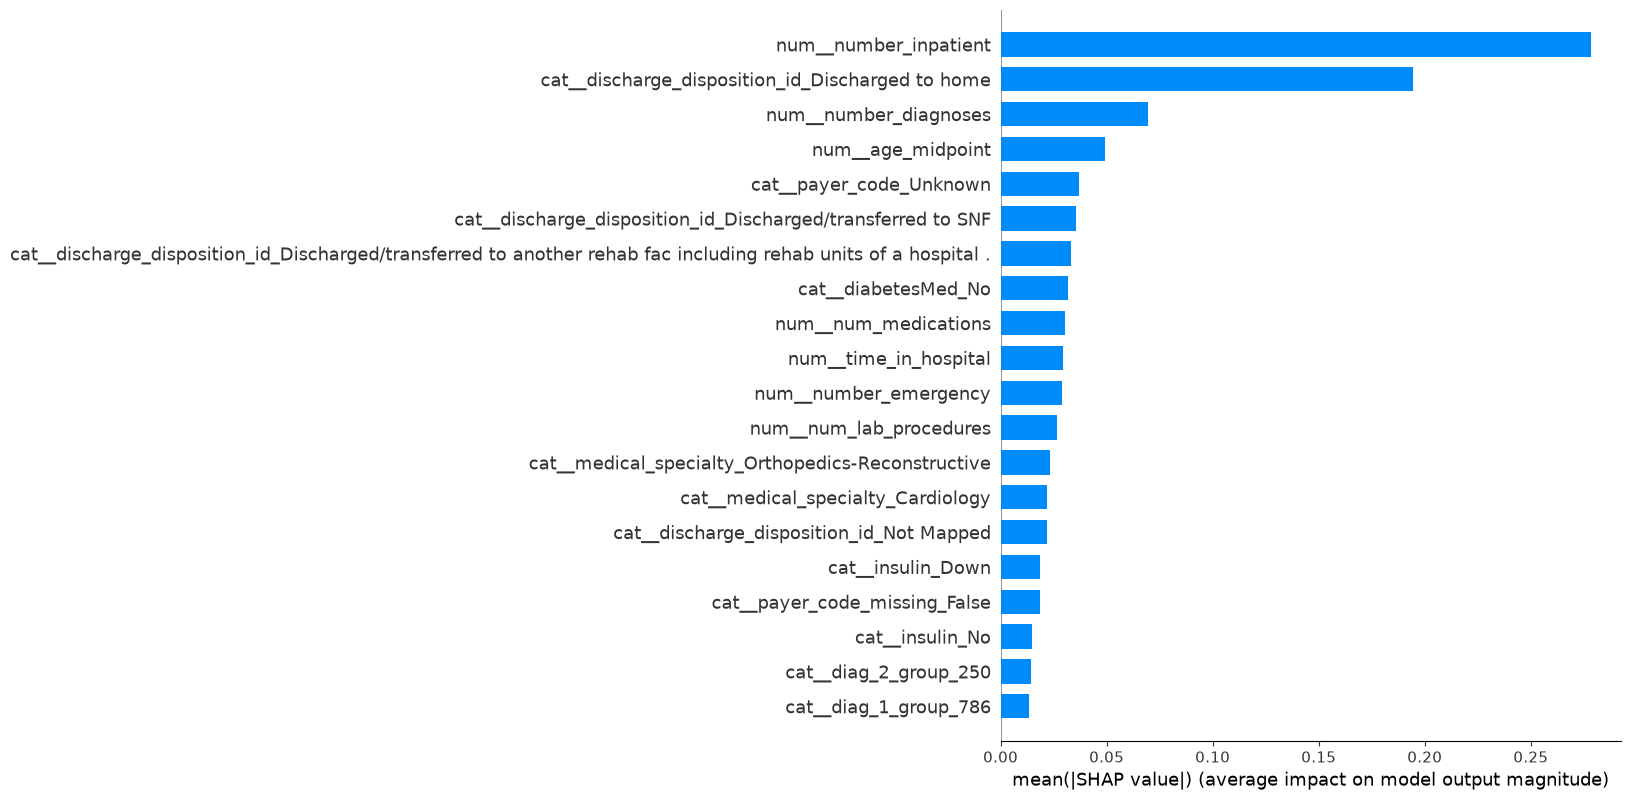

In [121]:
shap.summary_plot(
    xgb_shap_500,
    X_xgb_plot_500,
    plot_type="bar",
    max_display=20
)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


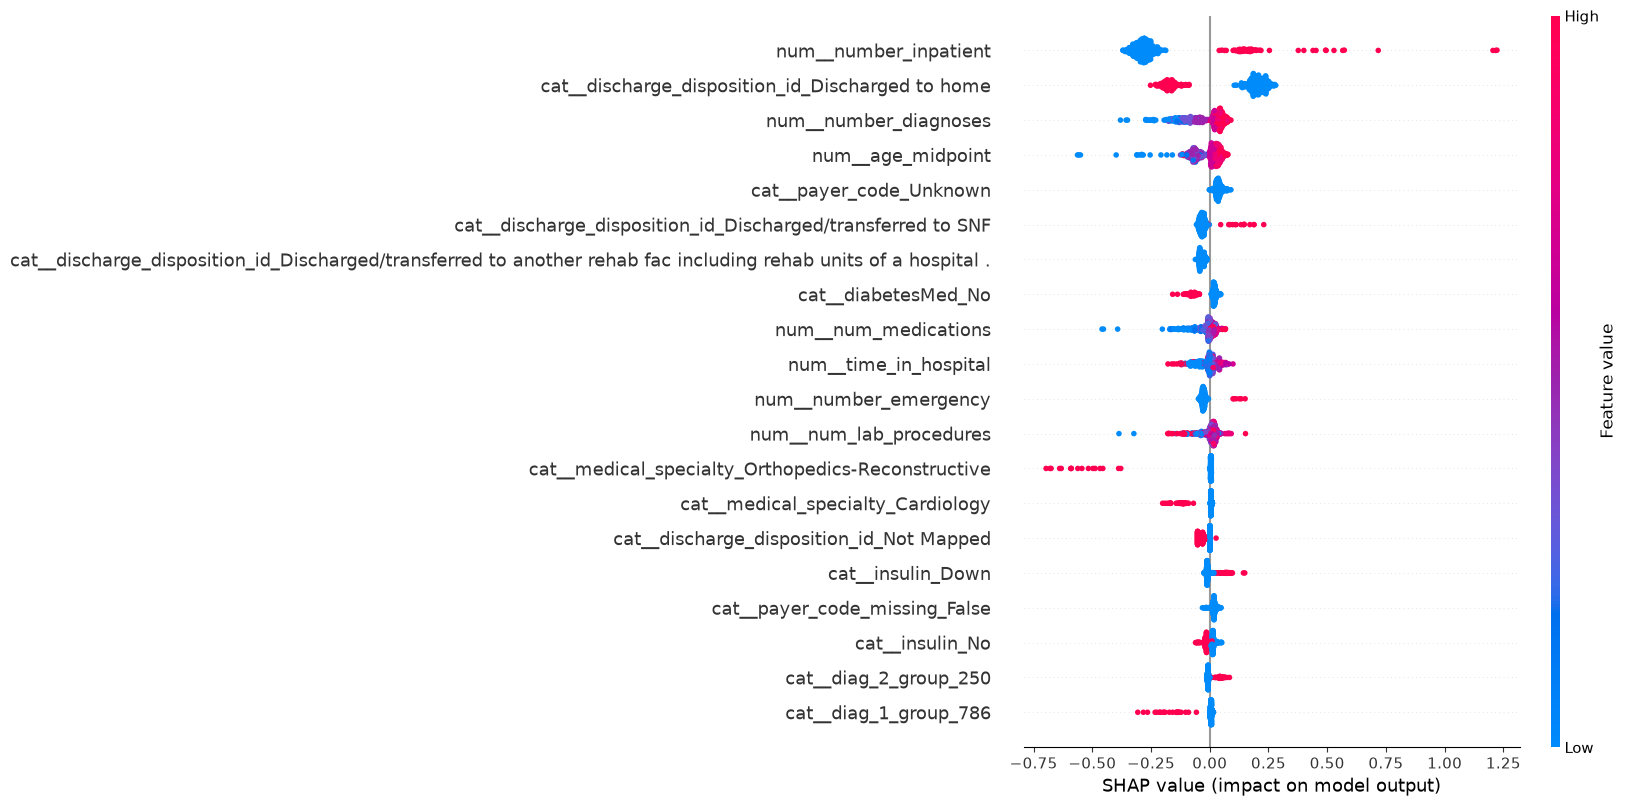

In [122]:
shap.summary_plot(
    xgb_shap_500,
    X_xgb_plot_500,
    max_display=20
)